<a href="https://www.kaggle.com/code/makrrc/spaceship-titanic-with-voting-ensemble?scriptVersionId=364327551" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
"""
Import from libraries that will be used in the project

"""

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# machine learning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import Perceptron
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn import *

print('Carregou as bibliotecas...')

Carregou as bibliotecas...


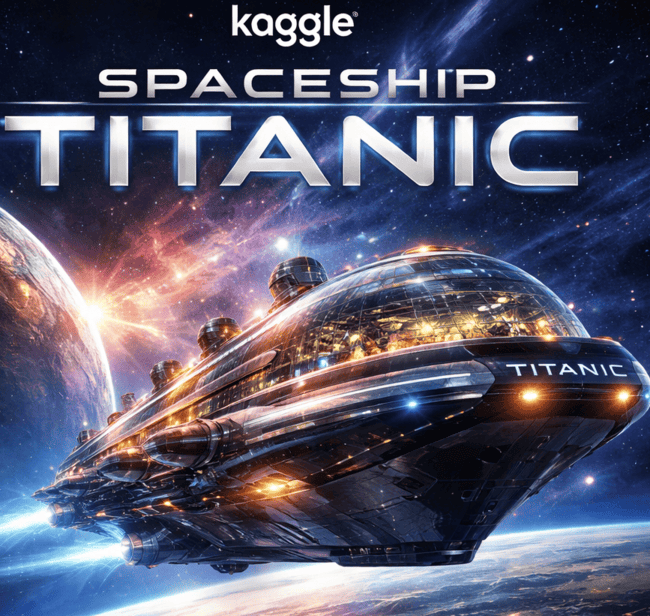

🚀 Spaceship Titanic: A Data Investigation Journey
Final Score: 0.80126 | Kaggle Competition

🎯 The Objective
To predict which passengers of the Spaceship Titanic were "transported" to an alternate dimension after an anomalous incident—a binary classification problem that, at first glance, seems simple, but hid subtle patterns that required forensic investigation of the data.

My goal wasn't just to run a model and hope for the best result. It was to understand the story the data told before letting any algorithm decide for me.

🛠️ O Processo: Detetive de Dados
1. Diagnóstico de nulos com lógica de negócio
Em vez de aplicar fillna(media) cegamente em todas as colunas, tratei cada variável como uma pergunta separada:

VIP: Analisei a proporção de VIPs por HomePlanet e descobri que Earth tinha 0% de VIPs — um padrão determinístico, não aleatório. Isso me permitiu imputar com confiança estatística, em vez de usar a moda geral ignorando o contexto.
Age: Aqui veio a parte mais interessante. Cruzando spendMoney == 0 com CryoSleep == False, encontrei um cluster denso de idades entre 0 e 12 anos (104 registros só na idade 0). A hipótese: crianças não gastam em serviços premium mesmo despertas. Validei calculando a mediana desse subgrupo específico (7 anos) e usei isso como regra de imputação segmentada — muito mais preciso que uma mediana global que diluiria esse sinal.

2. Purposeful Feature Engineering
I broke Cabin into deck, num, and side, applying one-hot encoding.
I created a family_group by extracting surnames from the PassengerId, hypothesizing that families tend to share the same destination.
I aggregated individual spending into spendMoney, creating a feature that captured "consumption behavior" as a proxy for passenger status/activity.

3. Cross-validation of hypotheses, not acceptance on faith

Each imputation decision was tested with groupby().median() and value_counts() before being applied—I wanted to see the pattern in the data, not assume it.

✅ What worked
Segmented imputation of Age (child vs. adult, via spendMoney + CryoSleep) captured a real signal that a simple imputation (global median) would have missed.
The deterministic rule of VIP == False for Earth eliminated noise from a variable that, if poorly handled, could introduce bias.
The decomposition of Cabin into deck and side revealed spatial patterns relevant to the destination.
❌ What didn't work (and what I learned)
Initial attempts to use KNN imputation on Age yielded worse results than the business rules approach—the data had too strong a categorical structure for a purely generic statistical method.
family_group as an isolated feature had a marginal impact—the signal was already partially captured by deck/side, revealing redundancy that I needed to prune to avoid overfitting.

🏁 Conclusion
The score wasn't the result of a complex model or brute-force computing—it was the result of deliberate, tested, and justified decisions at each stage of the pipeline. I prefer a simple model on well-understood data to a complex model on poorly interpreted data.

That, in the end, is the essence of data science: it's not about sophisticated algorithms, it's about asking the right questions before seeking the right answers.

**Library for working with time data types and task parallelization.**

In [2]:
##
import time
from joblib import Parallel, delayed

**model validation**# 

In [3]:
##

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.metrics import accuracy_score

print('Loaded the libraries...')

Loaded the libraries...


In [4]:
train_df = pd.read_csv("/kaggle/input/spaceship-titanic/train.csv")
print("Database loaded")

Database loaded


In [5]:
test_df = pd.read_csv("/kaggle/input/spaceship-titanic/test.csv")
print("Test database loaded")

Test database loaded


In [6]:
PassengerId = pd.read_csv("/kaggle/input/spaceship-titanic/test.csv")['PassengerId']
##test_df
PassengerId

0       0013_01
1       0018_01
2       0019_01
3       0021_01
4       0023_01
         ...   
4272    9266_02
4273    9269_01
4274    9271_01
4275    9273_01
4276    9277_01
Name: PassengerId, Length: 4277, dtype: object

In [7]:
# combine = [train_df, test_df]
# print("Training and test database are loaded")

In [8]:
# "After", train_df.shape, test_df.shape, combine[0].shape, combine[1].shape

In [9]:
"After", train_df.shape, test_df.shape

('After', (8693, 14), (4277, 13))

In [10]:
##Check the columns

train_df.columns.values

array(['PassengerId', 'HomePlanet', 'CryoSleep', 'Cabin', 'Destination',
       'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall', 'Spa',
       'VRDeck', 'Name', 'Transported'], dtype=object)

In [11]:
##Check the first records

train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [12]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [13]:
train_df.tail()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False
8692,9280_02,Europa,False,E/608/S,TRAPPIST-1e,44.0,False,126.0,4688.0,0.0,0.0,12.0,Propsh Hontichre,True


In [14]:
## Brings statistical information about the base

train_df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [15]:
## Correlation of columns to analyse

train_df.corr()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported
Age,1.000000,0.068723,0.130421,0.033133,0.123970,0.101007,-0.075026
RoomService,0.068723,1.000000,-0.015889,0.054480,0.010080,-0.019581,-0.244611
FoodCourt,0.130421,-0.015889,1.000000,-0.014228,0.221891,0.227995,0.046566
ShoppingMall,0.033133,0.054480,-0.014228,1.000000,0.013879,-0.007322,0.010141
Spa,0.123970,0.010080,0.221891,0.013879,1.000000,0.153821,-0.221131
VRDeck,0.101007,-0.019581,0.227995,-0.007322,0.153821,1.000000,-0.207075
Transported,-0.075026,-0.244611,0.046566,0.010141,-0.221131,-0.207075,1.000000


<AxesSubplot:>

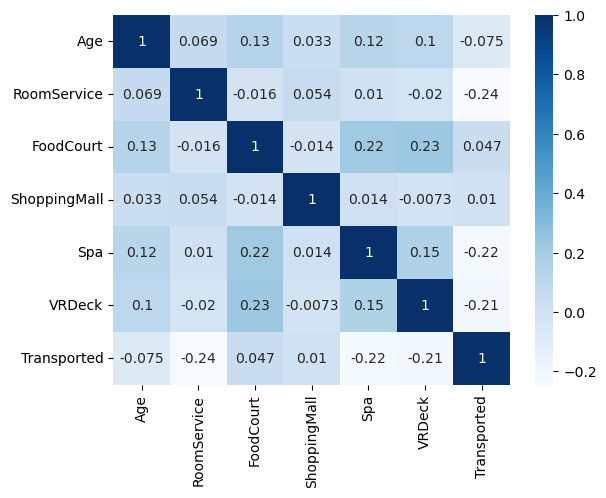

In [16]:
##Heatmap of columns correlation to analyse

sns.heatmap(train_df.corr(),cmap="Blues",annot=True)

In [17]:
##Total records

print("Total de: ",train_df['PassengerId'].count(), " registros")

Total de:  8693  registros


In [18]:
## Check for nulls in train_df base by column

train_df.isnull().sum().sort_values(ascending=False)

CryoSleep       217
ShoppingMall    208
VIP             203
HomePlanet      201
Name            200
Cabin           199
VRDeck          188
FoodCourt       183
Spa             183
Destination     182
RoomService     181
Age             179
PassengerId       0
Transported       0
dtype: int64

In [19]:
train_df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False


In [20]:
train_df['Cabin'].isna().sum()

199

In [21]:
train_df[train_df['Cabin'].isna()]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
15,0012_01,Earth,False,NaN,TRAPPIST-1e,31.0,False,32.0,0.0,876.0,0.0,0.0,Justie Pooles,False
93,0101_01,Mars,True,NaN,TRAPPIST-1e,31.0,False,0.0,0.0,0.0,0.0,0.0,Book Trad,True
103,0110_01,Europa,False,NaN,TRAPPIST-1e,32.0,False,0.0,410.0,6.0,3929.0,764.0,Graviph Aloubtled,False
222,0239_01,Mars,False,NaN,TRAPPIST-1e,37.0,False,637.0,0.0,0.0,92.0,319.0,Diedow Resty,False
227,0244_01,Mars,True,NaN,TRAPPIST-1e,43.0,False,0.0,0.0,0.0,0.0,0.0,Froos Sad,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8209,8772_02,Europa,False,NaN,55 Cancri e,53.0,False,0.0,1127.0,0.0,3939.0,NaN,Naosura Motled,False
8475,9057_01,Europa,False,NaN,55 Cancri e,36.0,True,132.0,3479.0,0.0,3786.0,0.0,Coxan Statch,False
8485,9069_03,Europa,True,NaN,55 Cancri e,25.0,False,0.0,0.0,0.0,0.0,0.0,Bath Brakeng,True
8509,9081_03,Earth,True,NaN,TRAPPIST-1e,1.0,False,0.0,0.0,0.0,0.0,0.0,Beula Clemondsey,False


deck/num/side

In [22]:
train_df.groupby('Cabin').size().sort_values(ascending=False).reset_index(name='quantidade')


,Cabin,quantidade
0,G/734/S,8
1,C/21/P,7
2,G/1368/P,7
3,B/82/S,7
4,G/981/S,7
...,...,...
6555,F/1245/P,1
6556,F/1244/S,1
6557,F/1243/S,1
6558,F/1243/P,1


## Ungroup Cabin column to deck/num/side in train_df base

In [23]:
train_df[['deck','num','side']] = train_df['Cabin'].str.split('/', expand=True)

In [24]:
test_df[['deck','num','side']] = test_df['Cabin'].str.split('/', expand=True)

In [25]:
train_df[['family_group','family_group_number']] = train_df['PassengerId'].str.split('_', expand=True)

In [26]:
test_df[['family_group','family_group_number']] = test_df['PassengerId'].str.split('_', expand=True)

In [27]:
# 1. Extrair o sobrenome do campo Name
train_df['Last_name'] = train_df['Name'].str.split(' ').str[-1]

In [28]:
# 1. Extrair o sobrenome do campo Name
test_df['Last_name'] = test_df['Name'].str.split(' ').str[-1]

In [29]:
train_df['Name'] = train_df['Name'].fillna('Unknown Unknown')
train_df['Last_name'] = train_df['Name'].str.split(' ').str[-1]

In [30]:
test_df['Name'] = test_df['Name'].fillna('Unknown Unknown')
test_df['Last_name'] = test_df['Name'].str.split(' ').str[-1]

In [31]:
train_df.isna().sum()

PassengerId              0
HomePlanet             201
CryoSleep              217
Cabin                  199
Destination            182
Age                    179
VIP                    203
RoomService            181
FoodCourt              183
ShoppingMall           208
Spa                    183
VRDeck                 188
Name                     0
Transported              0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [32]:
train_df.isna().sum()

PassengerId              0
HomePlanet             201
CryoSleep              217
Cabin                  199
Destination            182
Age                    179
VIP                    203
RoomService            181
FoodCourt              183
ShoppingMall           208
Spa                    183
VRDeck                 188
Name                     0
Transported              0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [33]:
train_df['family_group']

0       0001
1       0002
2       0003
3       0003
4       0004
        ... 
8688    9276
8689    9278
8690    9279
8691    9280
8692    9280
Name: family_group, Length: 8693, dtype: object

Passengers from the same group tend to have the same HomePlanet/Destination/Cabin.

In [34]:
train_df[
    ( train_df['CryoSleep'].isnull() ) 
    & ( train_df['ShoppingMall'].isnull() ) 
    # & ( train_df['HomePlanet'].isnull() ) 
    & ( train_df['Cabin'].isnull() ) 
    | ( train_df['Destination'].isnull() ) 
]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name
47,0045_02,Mars,True,F/10/P,NaN,19.0,False,0.0,0.0,0.0,0.0,0.0,Mass Chmad,True,F,10,P,0045,02,Chmad
128,0138_02,Earth,False,E/5/P,NaN,34.0,False,0.0,22.0,0.0,564.0,207.0,Monah Gambs,False,E,5,P,0138,02,Gambs
139,0152_01,Earth,False,F/32/P,NaN,41.0,False,0.0,0.0,0.0,0.0,607.0,Andan Estron,False,F,32,P,0152,01,Estron
347,0382_01,NaN,False,G/64/P,NaN,23.0,False,348.0,0.0,0.0,4.0,368.0,Blanie Floydendley,False,G,64,P,0382,01,Floydendley
430,0462_01,Earth,True,G/67/S,NaN,50.0,False,0.0,0.0,0.0,0.0,0.0,Ronia Sosanturney,False,G,67,S,0462,01,Sosanturney
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8372,8956_02,Earth,True,G/1453/P,NaN,20.0,False,0.0,0.0,0.0,0.0,0.0,Erina Bonnondry,True,G,1453,P,8956,02,Bonnondry
8551,9130_01,Mars,True,F/1765/S,NaN,41.0,False,0.0,0.0,0.0,0.0,0.0,Blers Corte,True,F,1765,S,9130,01,Corte
8616,9195_02,Mars,True,F/1779/S,NaN,33.0,False,0.0,0.0,0.0,0.0,0.0,Ceros Purle,True,F,1779,S,9195,02,Purle
8621,9197_02,Europa,False,C/308/P,NaN,41.0,True,0.0,7964.0,0.0,3238.0,5839.0,Aludram Platch,False,C,308,P,9197,02,Platch


In [35]:
train_df.loc[ :,  
    ( train_df.columns != 'PassengerId' ) 
    & ( train_df.columns != 'Name' ) 
    & ( train_df.columns != 'Cabin' ) 
]

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,deck,num,side,family_group,family_group_number,Last_name
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,False,B,0,P,0001,01,Ofracculy
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,True,F,0,S,0002,01,Vines
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,A,0,S,0003,01,Susent
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,A,0,S,0003,02,Susent
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,True,F,1,S,0004,01,Santantines
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,Europa,False,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,False,A,98,P,9276,01,Noxnuther
8689,Earth,True,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,False,G,1499,S,9278,01,Mondalley
8690,Earth,False,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,True,G,1500,S,9279,01,Connon
8691,Europa,False,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,False,E,608,S,9280,01,Hontichre


In [36]:
# train_df['total_money'] = train_df['RoomService'] + train_df['FoodCourt'] + train_df['ShoppingMall'] + train_df['Spa'] + train_df['VRDeck']

In [37]:
# test_df['total_money'] = test_df['RoomService'] + test_df['FoodCourt'] + test_df['ShoppingMall'] + test_df['Spa'] + test_df['VRDeck']

In [38]:
## Median values by columns

train_df.median()[1:]

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:3: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  This is separate from the ipykernel package so we can avoid doing imports until


CryoSleep                 0.0
Age                      27.0
VIP                       0.0
RoomService               0.0
FoodCourt                 0.0
ShoppingMall              0.0
Spa                       0.0
VRDeck                    0.0
Transported               1.0
num                     427.0
family_group           4630.0
family_group_number       1.0
dtype: float64

In [39]:
test_df.median()[1:]

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:1: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  """Entry point for launching an IPython kernel.


CryoSleep                 0.0
Age                      26.0
VIP                       0.0
RoomService               0.0
FoodCourt                 0.0
ShoppingMall              0.0
Spa                       0.0
VRDeck                    0.0
num                     442.0
family_group           4639.0
family_group_number       1.0
dtype: float64

In [40]:
## Info values ( Column, Non-Null, Count, Dtype ) by columns

train_df.info()
print('_'*40)
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PassengerId          8693 non-null   object 
 1   HomePlanet           8492 non-null   object 
 2   CryoSleep            8476 non-null   object 
 3   Cabin                8494 non-null   object 
 4   Destination          8511 non-null   object 
 5   Age                  8514 non-null   float64
 6   VIP                  8490 non-null   object 
 7   RoomService          8512 non-null   float64
 8   FoodCourt            8510 non-null   float64
 9   ShoppingMall         8485 non-null   float64
 10  Spa                  8510 non-null   float64
 11  VRDeck               8505 non-null   float64
 12  Name                 8693 non-null   object 
 13  Transported          8693 non-null   bool   
 14  deck                 8494 non-null   object 
 15  num                  8494 non-null   o

In [41]:
## Ungroup family from code and add to dataframe to know how many families and correlate with survivors
## train_df

# train_df['family_group'] = train_df['PassengerId'].str.split("_", n = 1, expand = True)[0]

In [42]:
## Ungroup family from code and add to dataframe to know how many families and correlate with survivors
## train_df

# test_df['family_group'] = test_df['PassengerId'].str.split("_", n = 1, expand = True)[0]

In [43]:
train_df['Spa']

0          0.0
1        549.0
2       6715.0
3       3329.0
4        565.0
         ...  
8688    1643.0
8689       0.0
8690       1.0
8691     353.0
8692       0.0
Name: Spa, Length: 8693, dtype: float64

In [44]:
train_df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P,0001,01,Ofracculy
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S,0002,01,Vines
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S,0003,01,Susent
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S,0003,02,Susent
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S,0004,01,Santantines
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,A,98,P,9276,01,Noxnuther
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,G,1499,S,9278,01,Mondalley
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,G,1500,S,9279,01,Connon
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False,E,608,S,9280,01,Hontichre


In [45]:
##Total de grupos com mais de um status para Transported

train_df.groupby('family_group_number').agg({'Transported': 'count'}).reset_index().query('Transported > 2')

,family_group_number,Transported
0,01,6217
1,02,1412
2,03,571
3,04,231
4,05,128
5,06,75
6,07,46
7,08,13


In [46]:
train_df[ train_df['family_group_number'] == '01' ]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P,0001,01,Ofracculy
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S,0002,01,Vines
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S,0003,01,Susent
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S,0004,01,Santantines
5,0005_01,Earth,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,0.0,Sandie Hinetthews,True,F,0,P,0005,01,Hinetthews
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8685,9275_01,Europa,False,A/97/P,TRAPPIST-1e,0.0,False,0.0,0.0,0.0,0.0,0.0,Polaton Conable,True,A,97,P,9275,01,Conable
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,A,98,P,9276,01,Noxnuther
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,G,1499,S,9278,01,Mondalley
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,G,1500,S,9279,01,Connon


<AxesSubplot:xlabel='CryoSleep,Transported'>

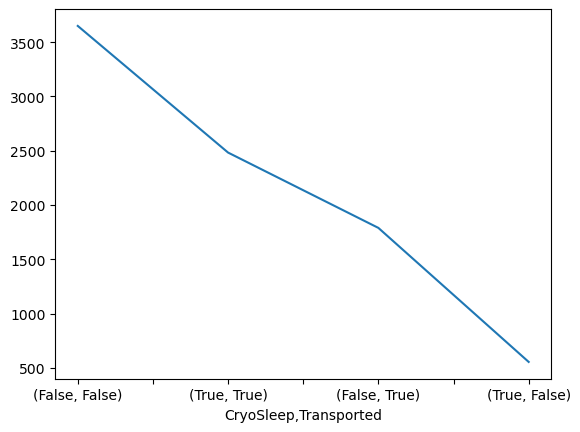

In [47]:
train_df[[ 'CryoSleep', 'Transported' ]].value_counts().plot()

In [48]:
##We have found that children under 12 years old have no expenses. Any child missing this information may have a total expense of 0.

train_df[(train_df['Age'] < 12) & (train_df['RoomService'] != 0) & (train_df['FoodCourt'] != 0) & (train_df['ShoppingMall'] !=0 ) & (train_df['Spa'] != 0) & (train_df['VRDeck'] != 0)]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name


In [49]:
##Now we will input the value 0 to all nan and null children in all services for the train.


train_df.loc[(train_df['Age'] < 12), ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']] = 0
train_df.loc[(train_df['Age'] < 18), ['VIP']] = False

In [50]:
##


test_df.loc[(test_df['Age'] < 12), ['RoomService','FoodCourt','ShoppingMall','Spa','VRDeck']] = 0
test_df.loc[(test_df['Age'] < 18), ['VIP']] = False

In [51]:
##We found that all records in the VIP column for individuals aged 17 or younger were filled.
train_df[(train_df['Age'] < 18) & (train_df['VIP'] == True)]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name


In [52]:
##Constatamos que Todos os registros de colunas monetárias para crianças até 12 anos foram imputados 0.

train_df[(train_df['Age'] < 12) & (train_df['Spa'].isnull())]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name


In [53]:
## Notamos que uma grande amostra de pessoas do Planeta Natal Europa estava em criogenia. Testamos a condição oposta.
# train_df[(train_df['HomePlanet'] != 'Europa') & (train_df['CryoSleep'] == False)]

We checked the age range of people using Homeplanet and VIP. And we discovered that VIPs are only in the 18 to 73 age range.

In [54]:
# np.sort(train_df[(train_df['HomePlanet'] == 'Mars') & (train_df['VIP'] == True)]['Age'].unique())

In [55]:
##We checked the age range of people using Homeplanet and VIP. And we discovered that VIPs are only in the 18 to 73 age range.

# np.sort(test_df[(test_df['HomePlanet'] == 'Mars') & (test_df['VIP'] == True)]['Age'].unique())

In [56]:
train_df[['family_group','PassengerId']].groupby('family_group')

In [57]:
test_df[['family_group','PassengerId']].groupby('family_group')

In [58]:
##train_df.isna().sum()
test_df.isna().sum()

PassengerId              0
HomePlanet              87
CryoSleep               93
Cabin                  100
Destination             92
Age                     91
VIP                     84
RoomService             75
FoodCourt               98
ShoppingMall            93
Spa                     93
VRDeck                  69
Name                     0
deck                   100
num                    100
side                   100
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [59]:
train_df.groupby("family_group").count()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group_number,Last_name
family_group,,,,,,,,,,,,,,,,,,,
0001,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
0002,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
0003,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2
0004,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
0005,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9275,3,3,2,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
9276,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
9278,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1


In [60]:
##We consulted all families that have at least one member on Cryosleep and those with more than one member.

family_group = train_df[train_df['CryoSleep'].isnull() & train_df.groupby('family_group')['family_group'].transform('size').gt(1)].sort_values('family_group')['family_group'].unique()
family_group

array(['0099', '0110', '0290', '0348', '0433', '0454', '0568', '0712',
       '0770', '0794', '1116', '1453', '1500', '1624', '1712', '1865',
       '1874', '1882', '2019', '2135', '2234', '2291', '2347', '2384',
       '2558', '2595', '2760', '2822', '3029', '3060', '3163', '3189',
       '3272', '3301', '3422', '3439', '3476', '3489', '3608', '3609',
       '3714', '3747', '3962', '4006', '4066', '4108', '4258', '4315',
       '4371', '4401', '4446', '4569', '4603', '4606', '4680', '4741',
       '4932', '4981', '5090', '5205', '5447', '5552', '5625', '5756',
       '5855', '5927', '6035', '6039', '6066', '6139', '6285', '6309',
       '6324', '6405', '6444', '6525', '6585', '6662', '6674', '6675',
       '6741', '6787', '6827', '6899', '7083', '7186', '7402', '7584',
       '7604', '7697', '7848', '7872', '7891', '7902', '8015', '8119',
       '8252', '8276', '8339', '8366', '8431', '8574', '8719', '8728',
       '8944', '9197', '9227', '9275'], dtype=object)

In [61]:
##We consulted all families that have at least one member on Cryosleep and those with more than one member.

family_group_test = test_df[train_df['CryoSleep'].isnull() & test_df.groupby('family_group')['family_group'].transform('size').gt(1)].sort_values('family_group')['family_group'].unique()
family_group_test

/opt/conda/lib/python3.7/site-packages/ipykernel_launcher.py:3: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  This is separate from the ipykernel package so we can avoid doing imports until


array(['0230', '0489', '0584', '0827', '0943', '1301', '1422', '1477',
       '1492', '1629', '2108', '2344', '2976', '3008', '3037', '3122',
       '3290', '3368', '3494', '4133', '4298', '4523', '5241', '5329',
       '5789', '6260', '6288', '6612', '6700', '6986', '7100', '7329',
       '7348', '7582', '8181', '8340', '8400', '8793', '8913'],
      dtype=object)

In [62]:
##I took an isolated case to create a filter that could capture rows that match the first row, `family_group`, and are not null.

train_df[(train_df['family_group'] == '0099') & (train_df['Cabin'].notnull())][:1]['Cabin']

91    F/19/P
Name: Cabin, dtype: object

In [63]:
#Estou atribuindo ao dataset o valor filtrado pelo código da família à cabine do primeiro membro da família diferente de nulo para todos que estiverem nulos



def cabinByFamilyGroup(base_df, groups):
    inicial = time.time()
    for group in groups:
        cabin_notnull = base_df[(base_df['family_group'] == group) & (base_df['Cabin'].notnull())]
        if len(cabin_notnull) > 0:
            cabin_str = cabin_notnull.iloc[0]['Cabin']
            base_df.loc[(base_df['family_group'] == group ) & ( base_df['Cabin'].isnull() ), 'Cabin'] = cabin_str

    print(" inicial train: ",inicial," ,Final train",time.time()," Duração train: ",time.time() - inicial)       
            
            
#cabinByFamilyGroup(train_df)  
#cabinByFamilyGroup(test_df)  


In [64]:
def process_group_parallel(train_df, groups):
    cabin_notnull = train_df[(train_df['family_group'] == group) & (train_df['Cabin'].notnull())]
    if len(cabin_notnull) > 0:
        cabin_str = cabin_notnull.iloc[0]['Cabin']
        train_df.loc[ ( train_df['family_group'] == group & train_df['Cabin'].isnull() ), 'Cabin'] = cabin_str

def cabinByFamilyGroup_parallel(train_df, groups):
    inicial = time.time()
    #groups = train_df['family_group'].unique()
    Parallel(n_jobs=-1, backend='multiprocessing')(delayed(process_group_parallel)(train_df, groups) for group in groups)
    print(" inicial train: ",inicial," ,Final train",time.time()," Duração train: ",time.time() - inicial)

In [65]:
#inicial = time.time()
cabinByFamilyGroup(test_df, family_group_test) 
#print(" inicial: ",inicial," ,Final ",time.time()," Duração: ",time.time() - inicial)

 inicial train:  1793473097.7595665  ,Final train 1793473097.886762  Duração train:  0.1271963119506836


In [66]:
#inicial = time.time()
cabinByFamilyGroup(train_df, family_group)  
#print(" inicial: ",inicial," ,Final ",time.time()," Duração: ",time.time() - inicial)

 inicial train:  1793473098.0382032  ,Final train 1793473098.501063  Duração train:  0.4628603458404541


In [67]:
##Here we confirm that everything is correct. It should return 0 lines.
train_df[(train_df['family_group'] == '0110') & (train_df['Cabin'].isnull())]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name


In [68]:
train_df.groupby("family_group")['PassengerId'].count()

family_group
0001    1
0002    1
0003    2
0004    1
0005    1
       ..
9275    3
9276    1
9278    1
9279    1
9280    2
Name: PassengerId, Length: 6217, dtype: int64

In [69]:
train_df.isnull().sum()

PassengerId              0
HomePlanet             201
CryoSleep              217
Cabin                  188
Destination            182
Age                    179
VIP                    158
RoomService            162
FoodCourt              171
ShoppingMall           189
Spa                    169
VRDeck                 165
Name                     0
Transported              0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [70]:
train_df[(train_df['Destination'] == 'TRAPPIST-1e') 
             & (train_df['RoomService'] == 0)
            & (train_df['FoodCourt'] == 0)
            & (train_df['ShoppingMall'] == 0)
            & (train_df['Spa'] == 0)
            & (train_df['VRDeck'] == 0)
            & (train_df['Transported'] == True)
        & (train_df['Transported'].isnull())]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name


In [71]:
train_df [(train_df['RoomService'] == 0)
            | (train_df['FoodCourt'] == 0)
            | (train_df['ShoppingMall'] == 0)
            | (train_df['Spa'] == 0)
            | (train_df['VRDeck'] == 0)]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P,0001,01,Ofracculy
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S,0003,01,Susent
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S,0003,02,Susent
5,0005_01,Earth,False,F/0/P,PSO J318.5-22,44.0,False,0.0,483.0,0.0,291.0,0.0,Sandie Hinetthews,True,F,0,P,0005,01,Hinetthews
6,0006_01,Earth,False,F/2/S,TRAPPIST-1e,26.0,False,42.0,1539.0,3.0,0.0,0.0,Billex Jacostaffey,True,F,2,S,0006,01,Jacostaffey
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False,A,98,P,9276,01,Noxnuther
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False,G,1499,S,9278,01,Mondalley
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True,G,1500,S,9279,01,Connon
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False,E,608,S,9280,01,Hontichre


In [72]:
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'].isnull()), 'VRDeck'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'].isnull()) & (train_df['VRDeck'] == 0), 'Spa'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'].isnull()) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'ShoppingMall'] = 0
train_df.loc [(train_df['RoomService'] == 0) & (train_df['FoodCourt'].isnull()) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'FoodCourt'] = 0
train_df.loc [(train_df['RoomService'].isnull()) & (train_df['FoodCourt'] == 0) & (train_df['ShoppingMall'] == 0) & (train_df['Spa'] == 0) & (train_df['VRDeck'] == 0), 'RoomService'] = 0

In [73]:
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'].isnull()), 'VRDeck'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'].isnull()) & (test_df['VRDeck'] == 0), 'Spa'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'].isnull()) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'ShoppingMall'] = 0
test_df.loc [(test_df['RoomService'] == 0) & (test_df['FoodCourt'].isnull()) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'FoodCourt'] = 0
test_df.loc [(test_df['RoomService'].isnull()) & (test_df['FoodCourt'] == 0) & (test_df['ShoppingMall'] == 0) & (test_df['Spa'] == 0) & (test_df['VRDeck'] == 0), 'RoomService'] = 0

In [74]:
train_df.isna().sum()

PassengerId              0
HomePlanet             201
CryoSleep              217
Cabin                  188
Destination            182
Age                    179
VIP                    158
RoomService            107
FoodCourt              108
ShoppingMall           108
Spa                    117
VRDeck                 109
Name                     0
Transported              0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [75]:
train_df[(train_df['PassengerId']=='0006_02')]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name
7,0006_02,Earth,True,G/0/S,TRAPPIST-1e,28.0,False,0.0,0.0,0.0,0.0,0.0,Candra Jacostaffey,True,G,0,S,0006,02,Jacostaffey


In [76]:
train_df['Destination'].unique()

array(['TRAPPIST-1e', 'PSO J318.5-22', '55 Cancri e', nan], dtype=object)

In [77]:
##Total de grupos familiares

np.count_nonzero(train_df['family_group'].unique().astype('int') )

6217

In [78]:
## Group the data by family group whether or not it was transported

##train_df[train_df[['family_group','Transported']].groupby(['family_group'], as_index=False).count().sort_values(by='family_group', ascending=True)['Transported'] > 2]

In [79]:
# ##Compare origin and destination (Earth) #Compare origin and destination (Europe)
# earth_trappist = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
# earth_55cancri_e = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
# earth_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Earth") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

In [80]:
# ##Compare origin and destination (Europe)
# europa_trappist = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
# europa_55cancri_e = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
# europa_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Europa") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

In [81]:
# ##Compare origin and destination (Europe)
# mars_trappist = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "TRAPPIST-1e") ]["PassengerId"].count()
# mars_55cancri_e = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "55 Cancri e") ]["PassengerId"].count()
# mars_pso_j318_22 = train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "PSO J318.5-22") ]["PassengerId"].count()

Here I tried to relate HomePlanet with Destination

to get the count for each destination and check

if there is a correlation with the target column Transported

Conclusion: I found no correlation.

In [82]:
# home_planet_destination = dict()
# home_planet_destination["earth_trappist"] = (earth_trappist)
# home_planet_destination["earth_55cancri_e"] = (earth_55cancri_e)
# home_planet_destination["earth_pso_j318_22"] = (earth_pso_j318_22)
# home_planet_destination["europa_trappist"] = (europa_trappist)
# home_planet_destination["europa_55cancri_e"] = (europa_55cancri_e)
# home_planet_destination["europa_pso_j318_22"] = (europa_pso_j318_22)
# home_planet_destination["mars_trappist"] = (mars_trappist)
# home_planet_destination["mars_55cancri_e"] = (mars_55cancri_e)
# home_planet_destination["mars_pso_j318_22"] = (mars_pso_j318_22)   

# home_planet_destination

In [83]:
# train_df[ (train_df["HomePlanet"] == "Mars") & (train_df["Destination"] == "55 Cancri e") & (train_df["Transported"] == False) ]["PassengerId"].count()

In [84]:
##Look up deck, side, number using the deck.
deck_num_side = train_df[['deck','side','num']][train_df[['deck','num','side']]["deck"] == "G"].sort_values(by=['deck','side','num'])
display(deck_num_side.drop_duplicates())

,deck,side,num
19,G,P,0
40,G,P,1
5835,G,P,1000
5839,G,P,1001
5843,G,P,1002
...,...,...,...
5792,G,S,994
5812,G,S,995
5820,G,S,996
5824,G,S,998


In [85]:
"""
print("Passageiros total:",train_df[['deck','PassengerId']].groupby("deck").count())
print("Passageiros transportados: ",train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count())
print("Percentual de passageiros transportados por deck: ",train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count() * 100
/ train_df[['deck','PassengerId']].groupby("deck").count(), "%" )


tabularTransportadosPorDeck = pd.Dataframe({"Percentual de passageiros transportados por deck: ":train_df[['deck','PassengerId']][train_df["Transported"]==True].groupby("deck").count() * 100
/ train_df[['deck','PassengerId']].groupby("deck").count()})
"""


'\nprint("Passageiros total:",train_df[[\'deck\',\'PassengerId\']].groupby("deck").count())\nprint("Passageiros transportados: ",train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count())\nprint("Percentual de passageiros transportados por deck: ",train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count() * 100\n/ train_df[[\'deck\',\'PassengerId\']].groupby("deck").count(), "%" )\n\n\ntabularTransportadosPorDeck = pd.Dataframe({"Percentual de passageiros transportados por deck: ":train_df[[\'deck\',\'PassengerId\']][train_df["Transported"]==True].groupby("deck").count() * 100\n/ train_df[[\'deck\',\'PassengerId\']].groupby("deck").count()})\n'

In [86]:
##Quantidade família por deck
train_df[["family_group","deck"]].groupby(["deck"]).count()

,family_group
deck,
A,256
B,779
C,747
D,478
E,876
F,2794
G,2559
T,5


In [87]:
##Family quantity per deck
##train_df[["family_group","deck"]].groupby(["family_group"]).count() > 1

In [88]:
train_df['deck'].unique()

array(['B', 'F', 'A', 'G', nan, 'E', 'D', 'C', 'T'], dtype=object)

In [89]:
train_df['num'].value_counts().unique()

array([28, 22, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10,  9,  8,  7,
        6,  5,  4,  3,  2,  1])

In [90]:
train_df.isna().sum()

PassengerId              0
HomePlanet             201
CryoSleep              217
Cabin                  188
Destination            182
Age                    179
VIP                    158
RoomService            107
FoodCourt              108
ShoppingMall           108
Spa                    117
VRDeck                 109
Name                     0
Transported              0
deck                   199
num                    199
side                   199
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [91]:
###train_df['PassengerId'].groupby('family_group').count()

In [92]:
## These are the cabins, Shopping Mall and Room Service where passengers were transported

cabin_transported = train_df[['Cabin','Transported']].groupby(['Cabin'], as_index=False).mean().sort_values(by='Transported', ascending=False)
ShoppingMall_transported = train_df[['ShoppingMall','Transported']].groupby(['ShoppingMall'], as_index=False).mean().sort_values(by='Transported', ascending=False)
RoomService_transported = train_df[['RoomService','Transported']].groupby(['RoomService'], as_index=False).mean().sort_values(by='Transported', ascending=False)

In [93]:
## These are the cabins, Shopping Mall and Room Service that had no passengers transported

cabin_not_transported = pd.DataFrame()
ShoppingMall_not_transported = pd.DataFrame()
RoomService_not_transported =pd.DataFrame()

cabin_not_transported['cabin_not_transported'] = cabin_transported.loc[cabin_transported['Transported'] == 0].Cabin.unique()
ShoppingMall_not_transported['ShoppingMall_not_transported'] = ShoppingMall_transported.loc[ShoppingMall_transported['Transported'] == 0].ShoppingMall.unique()
RoomService_not_transported['RoomService_not_transported'] = RoomService_transported.loc[RoomService_transported['Transported'] == 0].RoomService.unique()


In [94]:
print(" Cabins in which people were not transported: ", np.count_nonzero(cabin_not_transported) ) 
print(" ShoppingMall_transported where people were not transported: ", np.count_nonzero(ShoppingMall_not_transported) )
print(" RoomService in which people were not transported: ", np.count_nonzero(RoomService_not_transported) )

 Cabins in which people were not transported:  3166
 ShoppingMall_transported where people were not transported:  499
 RoomService in which people were not transported:  851


In [95]:
cabin_not_transported

,cabin_not_transported
0,E/139/P
1,E/122/S
2,G/208/S
3,E/10/P
4,G/1497/P
...,...
3161,F/797/S
3162,F/1077/P
3163,F/1075/P
3164,F/1073/P


In [96]:
# test_df['cabin_not_transported'] = 0
# test_df['ShoppingMall_not_transported'] = 0
# test_df['RoomService_not_transported'] = 0
test_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,deck,num,side,family_group,family_group_number,Last_name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning,G,3,S,0013,01,Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers,F,4,S,0018,01,Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus,C,0,S,0019,01,Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter,C,1,S,0021,01,Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez,F,5,S,0023,01,Harperez


In [97]:
# ## Alternative code below
# # Find rows where the cabin is not transported
# mask = train_df['Cabin'].isin(cabin_not_transported['cabin_not_transported'])

# # Set the values of the 'cabin_not_transported' column to 1 where the mask is True, 0 otherwise
# train_df.loc[mask, 'cabin_not_transported'] = 1
# train_df.loc[~mask, 'cabin_not_transported'] = 0


In [98]:
# ## Alternative code below
# # Find rows where the cabin is not transported
# mask = test_df['Cabin'].isin(cabin_not_transported['cabin_not_transported'])

# # Set the values of the 'cabin_not_transported' column to 1 where the mask is True, 0 otherwise
# test_df.loc[mask, 'cabin_not_transported'] = 1
# test_df.loc[~mask, 'cabin_not_transported'] = 0


Alternative code below
Find rows where the ShoppingMall is not transported
This is interesting. Could this feature be causing harm to the final result?

In [99]:

# mask = train_df['ShoppingMall'].isin(ShoppingMall_not_transported['ShoppingMall_not_transported'])

# # Set the values of the 'ShoppingMall_not_transported' column to 1 where the mask is True, 0 otherwise
# train_df.loc[mask, 'ShoppingMall_not_transported'] = 1
# train_df.loc[~mask, 'ShoppingMall_not_transported'] = 0

In [100]:
# ## Alternative code below
# # Find rows where the ShoppingMall is not transported
# mask = test_df['ShoppingMall'].isin(ShoppingMall_not_transported['ShoppingMall_not_transported'])

# # Set the values of the 'ShoppingMall_not_transported' column to 1 where the mask is True, 0 otherwise
# test_df.loc[mask, 'ShoppingMall_not_transported'] = 1
# test_df.loc[~mask, 'ShoppingMall_not_transported'] = 0

In [101]:
# ## Alternative code below
# # Find rows where the RoomService is not transported
# mask = train_df['RoomService'].isin(RoomService_not_transported['RoomService_not_transported'])

# # Set the values of the 'RoomService_not_transported' column to 1 where the mask is True, 0 otherwise
# train_df.loc[mask, 'RoomService_not_transported'] = 1
# train_df.loc[~mask, 'RoomService_not_transported'] = 0

In [102]:
# ## Alternative code below
# # Find rows where the RoomService is not transported
# mask = test_df['RoomService'].isin(RoomService_not_transported['RoomService_not_transported'])

# # Set the values of the 'RoomService_not_transported' column to 1 where the mask is True, 0 otherwise
# test_df.loc[mask, 'RoomService_not_transported'] = 1
# test_df.loc[~mask, 'RoomService_not_transported'] = 0

In [103]:
## See if the column is populated correctly by checking the registration by sampling

train_df[train_df['Cabin'] == 'G/328/S']

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name
1929,2063_01,Earth,True,G/328/S,PSO J318.5-22,38.0,False,0.0,0.0,0.0,0.0,0.0,Mistie Leonaldez,False,G,328,S,2063,01,Leonaldez


In [104]:
# ## See if the column is populated correctly by checking the registration by sampling

# train_df[train_df['ShoppingMall_not_transported'] == 1]

In [105]:
## See if the column is populated correctly by checking the registration by sampling

train_df[train_df['RoomService'] == 570.]

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name
8241,8805_01,Earth,False,F/1815/P,PSO J318.5-22,37.0,False,570.0,0.0,7.0,107.0,0.0,Elindy Rasmussony,False,F,1815,P,8805,01,Rasmussony


In [106]:
## Create column with people who were in these cabins that were not affected

cabin_cryosleeped = train_df[train_df['CryoSleep'] == True]['Cabin'].unique()

total_cabin_criosleeps = np.count_nonzero(cabin_cryosleeped)

print(" Cabines para CryoSleep: ", np.count_nonzero(cabin_cryosleeped))

 Cabines para CryoSleep:  2439


In [107]:
## Total cabins for cryosleeps

total_cabin = np.count_nonzero( train_df['Cabin'].unique() )

print("Total de cabines: ",total_cabin," - cabines para criosleeps: ",total_cabin_criosleeps," -  Percentual cabines criosleeps: ", (total_cabin_criosleeps * 100 / total_cabin)," %")

Total de cabines:  6561  - cabines para criosleeps:  2439  -  Percentual cabines criosleeps:  37.174211248285324  %


In [108]:
## Total cabins

total_cabin = np.count_nonzero( train_df['Cabin'].unique() )

print("Total de cabines: ",total_cabin," - cabines para criosleeps: ",total_cabin_criosleeps," -  Percentual cabines criosleeps: ", (total_cabin_criosleeps * 100 / total_cabin)," %")

Total de cabines:  6561  - cabines para criosleeps:  2439  -  Percentual cabines criosleeps:  37.174211248285324  %


In [109]:
##  Create grid with correlation comparisons between bank columns

##g = sns.PairGrid(train_df, hue="Transported")
##g.map_diag(sns.scatterplot)
##g.map_offdiag(sns.scatterplot)
##g.add_legend()

print("continue...")

continue...


In [110]:
## Premises:
## Some cabins were not transported
## Drop PassengerId, Name columns that have no information
## Family_group has no null values
## Spa, VRDeck, ShoppingMall, Vip have a low correlation with transported passengers (Really?).
## Who're CryoSleep don't spend money

In [111]:
train_df['Transported']

0       False
1        True
2       False
3       False
4        True
        ...  
8688    False
8689    False
8690     True
8691    False
8692     True
Name: Transported, Length: 8693, dtype: bool

In [112]:
train_df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported,deck,num,side,family_group,family_group_number,Last_name
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False,B,0,P,0001,01,Ofracculy
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True,F,0,S,0002,01,Vines
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False,A,0,S,0003,01,Susent
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False,A,0,S,0003,02,Susent
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True,F,1,S,0004,01,Santantines


<AxesSubplot:>

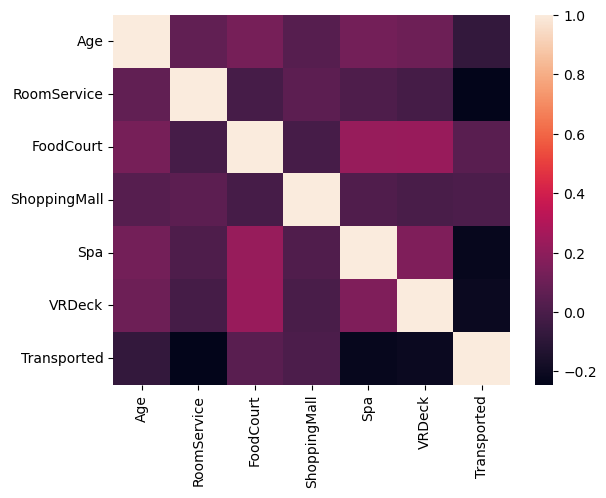

In [113]:
## Numerical correlation between columns

sns.heatmap(train_df.corr())

In [114]:
## Convert columns from object to float

train_df['family_group'] = train_df['family_group'].str.replace(',','.').astype(float)
train_df['num'] = train_df['num'].str.replace(',','.').astype(float)

In [115]:
## Convert columns from object to float

test_df['family_group'] = test_df['family_group'].str.replace(',','.').astype(float)
test_df['num'] = test_df['num'].str.replace(',','.').astype(float)

In [116]:
## Let's check if there were passengers alone

groupby_family_group = train_df.groupby('family_group').count()['PassengerId']

print("Total de famílias: ",groupby_family_group.count(), " Percentual de grupos de pessoas sozinhas: ",( ( groupby_family_group.loc[groupby_family_group == 1].count() * 100 ) / groupby_family_group.count() )," %"  )

Total de famílias:  6217  Percentual de grupos de pessoas sozinhas:  77.28808106803925  %


In [117]:
#Let's work about null values

test_df.isnull().sum()

PassengerId              0
HomePlanet              87
CryoSleep               93
Cabin                   97
Destination             92
Age                     91
VIP                     84
RoomService             54
FoodCourt               67
ShoppingMall            62
Spa                     52
VRDeck                  42
Name                     0
deck                   100
num                    100
side                   100
family_group             0
family_group_number      0
Last_name                0
dtype: int64

In [118]:
##Complete the NAN in deck, num and side

test_df["deck"].fillna("Unknown", inplace=True)
test_df["num"].fillna("Unknown", inplace=True)
test_df["side"].fillna("Unknown", inplace=True)

In [119]:
##Complete the NAN in deck, num and side

train_df["deck"].fillna("Unknown", inplace=True)
train_df["num"].fillna("Unknown", inplace=True)
train_df["side"].fillna("Unknown", inplace=True)

In [120]:
##  Filling NaN, null or etc values in train_df

train_df["CryoSleep"].fillna(False)
train_df["Age"].fillna(train_df["Age"].median())
train_df["VIP"].fillna(False)
##test_df["HomePlanet"].fillna(0)

train_df["RoomService"].fillna( float( train_df["RoomService"].mean() ), inplace=True)
train_df["FoodCourt"].fillna( float( train_df["FoodCourt"].mean() ), inplace=True)
train_df["ShoppingMall"].fillna( float( train_df["ShoppingMall"].mean() ), inplace=True)
train_df["Spa"].fillna( float( train_df["Spa"].mean() ), inplace=True)
train_df["VRDeck"].fillna( float( train_df["VRDeck"].mean() ), inplace=True)
train_df = train_df.fillna(train_df.mode())

In [121]:
##  Filling NaN, null or etc values in train_df

test_df["CryoSleep"].fillna(False)
test_df["Age"].fillna(train_df["Age"].median())
test_df["VIP"].fillna(False)
##test_df["HomePlanet"].fillna(0)

test_df["RoomService"].fillna( float( test_df["RoomService"].mean() ), inplace=True)
test_df["FoodCourt"].fillna( float( test_df["FoodCourt"].mean() ), inplace=True)
test_df["ShoppingMall"].fillna( float( test_df["ShoppingMall"].mean() ), inplace=True)
test_df["Spa"].fillna( float( test_df["Spa"].mean() ), inplace=True)
test_df["VRDeck"].fillna( float( test_df["VRDeck"].mean() ), inplace=True)
test_df = test_df.fillna(test_df.mode())

In [122]:
# ##  Filling NaN, null or etc values in test_df

# test_df["CryoSleep"].fillna(False)
# test_df["Age"].fillna(train_df["Age"].median())
# test_df["VIP"].fillna(False)
# ##test_df["HomePlanet"].fillna(0)

# test_df["RoomService"].fillna( float( test_df["RoomService"].mean() ), inplace=True)
# test_df["FoodCourt"].fillna( float( test_df["FoodCourt"].mean() ), inplace=True)
# test_df["ShoppingMall"].fillna( float( test_df["ShoppingMall"].mean() ), inplace=True)
# test_df["Spa"].fillna( float( test_df["Spa"].mean() ), inplace=True)
# test_df["VRDeck"].fillna( float( test_df["VRDeck"].mean() ), inplace=True)
# test_df = test_df.fillna(test_df.mode())

In [123]:
# train_df['spendMoney'] = train_df['RoomService'] + train_df['FoodCourt'] + train_df['ShoppingMall'] + train_df['Spa']
# train_df

In [124]:
# test_df['spendMoney'] = test_df['RoomService'] + test_df['FoodCourt'] + test_df['ShoppingMall'] + test_df['Spa']
# test_df

In [125]:
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

for col in spend_cols:
    train_df[col] = train_df[col].fillna(0)
    test_df[col] = test_df[col].fillna(0)

train_df['spendMoney'] = train_df[spend_cols].sum(axis=1)
test_df['spendMoney'] = test_df[spend_cols].sum(axis=1)

In [126]:
train_df.shape

(8693, 21)

In [127]:
##Funny. If the guy is a VIP, he is not from the earth
##display( train_df.query( 'HomePlanet == "Earth" and VIP == True' ) ) 
display( test_df.query( 'HomePlanet == "Earth" and VIP == True' ) ) 

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,deck,num,side,family_group,family_group_number,Last_name,spendMoney


In [128]:
##If you're from the Earth, you're not a VIP.
train_df.loc[(train_df['VIP'].isnull()) & (train_df['HomePlanet'] == 'Earth'),'VIP'] = 0
test_df.loc[(test_df['VIP'].isnull()) & (test_df['HomePlanet'] == 'Earth'),'VIP'] = 0

In [129]:
##Who're cryosleep don't spend money. Who're spending money don't are cryosleep

train_df.loc[(train_df['CryoSleep'].isna()) & (train_df['spendMoney'] == 0), 'CryoSleep'] = 1
train_df.loc[(train_df['CryoSleep'].isna()) & (train_df['spendMoney'] > 0), 'CryoSleep'] = 0

In [130]:
test_df.loc[(test_df['CryoSleep'].isna()) & (test_df['spendMoney'] == 0), 'CryoSleep'] = 1
test_df.loc[(test_df['CryoSleep'].isna()) & (test_df['spendMoney'] > 0), 'CryoSleep'] = 0

In [131]:
train_df.loc[train_df['CryoSleep'].isna(),['RoomService','FoodCourt','ShoppingMall','VRDeck', 'Spa']]

,RoomService,FoodCourt,ShoppingMall,VRDeck,Spa


In [132]:
train_df.isna().sum()

PassengerId              0
HomePlanet             201
CryoSleep                0
Cabin                  188
Destination            182
Age                    179
VIP                     76
RoomService              0
FoodCourt                0
ShoppingMall             0
Spa                      0
VRDeck                   0
Name                     0
Transported              0
deck                     0
num                      0
side                     0
family_group             0
family_group_number      0
Last_name                0
spendMoney               0
dtype: int64

In [133]:
##  View the HomePlanet column to see what values are contained

train_df['HomePlanet'].unique()

array(['Europa', 'Earth', 'Mars', nan], dtype=object)

In [134]:
## Create a list with the values that will be replaced and the values that will replace

# HomePlanet_mapping = {"Europa":1,"Earth":2,"Mars":3}
# HomePlanet_mapping

In [135]:
train_df = pd.get_dummies(train_df, columns=['deck'], prefix='deck')
train_df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,spendMoney,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T,deck_Unknown
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,...,0.0,0,1,0,0,0,0,0,0,0
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,...,736.0,0,0,0,0,0,1,0,0,0
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,...,10383.0,1,0,0,0,0,0,0,0,0
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,...,5176.0,1,0,0,0,0,0,0,0,0
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,...,1091.0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,...,8536.0,1,0,0,0,0,0,0,0,0
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,...,0.0,0,0,0,0,0,0,1,0,0
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,...,1873.0,0,0,0,0,0,0,1,0,0
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,...,4637.0,0,0,0,0,1,0,0,0,0


In [136]:
test_df = pd.get_dummies(test_df, columns=['deck'], prefix='deck')
test_df

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,spendMoney,deck_A,deck_B,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T,deck_Unknown
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,...,0.0,0,0,0,0,0,0,1,0,0
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,...,2832.0,0,0,0,0,0,1,0,0,0
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,...,0.0,0,0,1,0,0,0,0,0,0
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,...,7418.0,0,0,1,0,0,0,0,0,0
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,...,645.0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,9266_02,Earth,True,G/1496/S,TRAPPIST-1e,34.0,False,0.0,0.0,0.0,...,0.0,0,0,0,0,0,0,1,0,0
4273,9269_01,Earth,False,NaN,TRAPPIST-1e,42.0,False,0.0,847.0,17.0,...,1018.0,0,0,0,0,0,0,0,0,1
4274,9271_01,Mars,True,D/296/P,55 Cancri e,NaN,False,0.0,0.0,0.0,...,0.0,0,0,0,1,0,0,0,0,0
4275,9273_01,Europa,False,D/297/P,NaN,NaN,False,0.0,2680.0,0.0,...,3203.0,0,0,0,1,0,0,0,0,0


In [137]:
## Convert categorical / HomePlanet data to numeric in train_df

# train_df = train_df.replace(HomePlanet_mapping)
# train_df.head()

In [138]:
## Convert categorical / HomePlanet data to numeric in test_df

# test_df = test_df.replace(HomePlanet_mapping)
# test_df.head()

In [139]:
# Regra 1: CryoSleep == False e spendMoney == 0 -> provável criança
median_child_age = train_df.loc[
    (train_df['spendMoney'] == 0) & (train_df['CryoSleep'] == False), 'Age'
].median()

median_child_age

7.0

In [140]:
for df in [train_df, test_df]:
    mask_child = (df['Age'].isna()) & (df['spendMoney'] == 0) & (df['CryoSleep'] == False)
    df.loc[mask_child, 'Age'] = median_child_age

    # Para os nulos restantes (não se encaixam nesse padrão), usa mediana por HomePlanet
    df['Age'] = df['Age'].fillna(
        df.groupby('HomePlanet')['Age'].transform('median')
    )
    
    # Fallback final (mediana geral)
    df['Age'] = df['Age'].fillna(df['Age'].median())

In [141]:
train_df = pd.get_dummies(train_df,columns = ['HomePlanet'])
train_df

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,1,0
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,...,0,0,0,1,0,0,0,1,0,0
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,...,0,0,0,0,0,0,0,0,1,0
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,...,0,0,0,0,0,0,0,0,1,0
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,...,0,0,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,9276_01,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,...,0,0,0,0,0,0,0,0,1,0
8689,9278_01,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,...,0,0,0,0,1,0,0,1,0,0
8690,9279_01,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,...,0,0,0,0,1,0,0,1,0,0
8691,9280_01,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,...,0,0,1,0,0,0,0,0,1,0


In [142]:
test_df = pd.get_dummies(test_df,columns = ['HomePlanet'])
test_df

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars
0,0013_01,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,...,0,0,0,0,1,0,0,1,0,0
1,0018_01,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,...,0,0,0,1,0,0,0,1,0,0
2,0019_01,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,...,1,0,0,0,0,0,0,0,1,0
3,0021_01,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,...,1,0,0,0,0,0,0,0,1,0
4,0023_01,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,...,0,0,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,9266_02,True,G/1496/S,TRAPPIST-1e,34.0,False,0.0,0.0,0.0,0.0,...,0,0,0,0,1,0,0,1,0,0
4273,9269_01,False,NaN,TRAPPIST-1e,42.0,False,0.0,847.0,17.0,10.0,...,0,0,0,0,0,0,1,1,0,0
4274,9271_01,True,D/296/P,55 Cancri e,27.0,False,0.0,0.0,0.0,0.0,...,0,1,0,0,0,0,0,0,0,1
4275,9273_01,False,D/297/P,NaN,32.0,False,0.0,2680.0,0.0,0.0,...,0,1,0,0,0,0,0,0,1,0


In [143]:
## Join the modified bases in combine

# combine = [train_df, test_df]
# combine

In [144]:
## Drop PassengerId and Name columns in test_df

##test_df = test_df.drop(['Name'], axis=1)
train_df.head()

,PassengerId,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,...,deck_C,deck_D,deck_E,deck_F,deck_G,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars
0,0001_01,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,1,0
1,0002_01,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,...,0,0,0,1,0,0,0,1,0,0
2,0003_01,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,...,0,0,0,0,0,0,0,0,1,0
3,0003_02,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,...,0,0,0,0,0,0,0,0,1,0
4,0004_01,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,...,0,0,0,1,0,0,0,1,0,0


In [145]:
## Analyze the Destinations possibles

#train_df['Destination'].unique()

In [146]:
# destination = {'TRAPPIST-1e':'1','PSO J318.5-22':'2',
#                '55 Cancri e':'3','0':'0','1':'0'}

In [147]:
# train_df = train_df.replace(destination)
# train_df.head()

In [148]:
# test_df = test_df.replace(destination)
# test_df.head()

In [149]:
train_df['Destination'] = train_df['Destination'].fillna('Unknown')
test_df['Destination'] = test_df['Destination'].fillna('Unknown')

In [150]:
test_df = pd.get_dummies(test_df, columns=['Destination'], prefix='dest')

In [151]:
train_df = pd.get_dummies(train_df, columns=['Destination'], prefix='dest')

In [152]:
# Garantir que treino e teste tenham as mesmas colunas
test_df = test_df.reindex(columns=train_df.columns, fill_value=0)

In [153]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 34 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PassengerId          8693 non-null   object 
 1   CryoSleep            8693 non-null   object 
 2   Cabin                8505 non-null   object 
 3   Age                  8693 non-null   float64
 4   VIP                  8617 non-null   object 
 5   RoomService          8693 non-null   float64
 6   FoodCourt            8693 non-null   float64
 7   ShoppingMall         8693 non-null   float64
 8   Spa                  8693 non-null   float64
 9   VRDeck               8693 non-null   float64
 10  Name                 8693 non-null   object 
 11  Transported          8693 non-null   bool   
 12  num                  8693 non-null   object 
 13  side                 8693 non-null   object 
 14  family_group         8693 non-null   float64
 15  family_group_number  8693 non-null   o

In [154]:
## Drop PassengerId and Name columns in train_df

train_df = train_df.drop(['PassengerId','Name'], axis=1)
train_df.head()

test_df = test_df.drop(['PassengerId'], axis=1)

##X_train = train_df
##X_train.drop("Transported", axis=1)
##X_train

In [155]:
# ## Create a list with the values that will be replaced and the values that will replace

# Side_mapping = {"P":1,"S":2,"0":0}
# Side_mapping

In [156]:
# ## Create a list with the values that will be replaced and the values that will replace

# Deck_mapping = {"B":1,"F":2,"A":3, 'G':4, 'E':5,'D':6,'C':7,'T':8,'0':0}
# Deck_mapping

In [157]:
# ## Convert categorical/Deck data to numeric in test_df

# # test_df = test_df.replace(Deck_mapping)
# test_df = test_df.replace(Side_mapping)
# test_df.head()

In [158]:
# ## Convert categorical/Deck data to numeric in train_df

# # train_df = train_df.replace(Deck_mapping)
# train_df = train_df.replace(Side_mapping)
# train_df.head()

In [159]:
for df in [train_df, test_df]:
    df["side_missing"] = df["side"].isna().astype(int)  # flag de ausência
    df["side"] = df["side"].map({"P": 1, "S": 2}).fillna(0)

In [160]:
train_df.head()

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
0,False,B/0/P,39.0,False,0.0,0.0,0.0,0.0,0.0,False,...,0,0,0,1,0,0,0,1,0,0
1,False,F/0/S,24.0,False,109.0,9.0,25.0,549.0,44.0,True,...,0,0,1,0,0,0,0,1,0,0
2,False,A/0/S,58.0,True,43.0,3576.0,0.0,6715.0,49.0,False,...,0,0,0,1,0,0,0,1,0,0
3,False,A/0/S,33.0,False,0.0,1283.0,371.0,3329.0,193.0,False,...,0,0,0,1,0,0,0,1,0,0
4,False,F/1/S,16.0,False,303.0,70.0,151.0,565.0,2.0,True,...,0,0,1,0,0,0,0,1,0,0


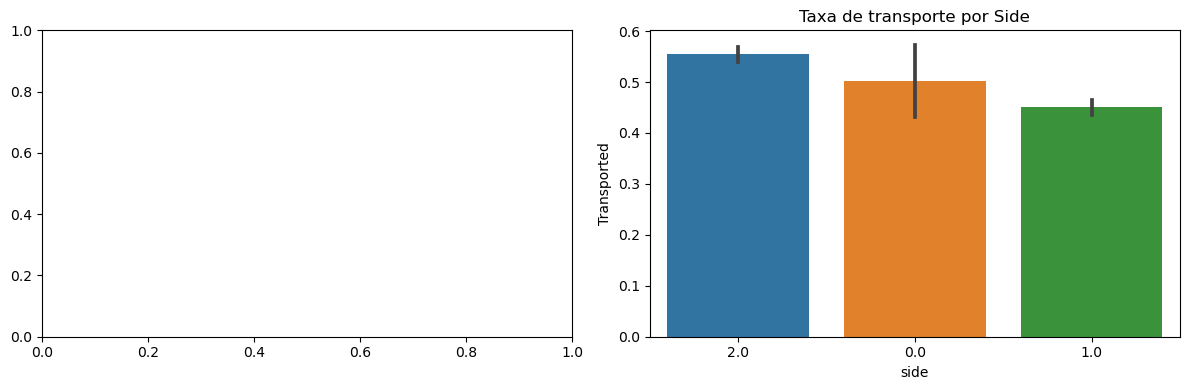

In [161]:
import seaborn as sns
import matplotlib.pyplot as plt

# Ordena os decks pela taxa de transporte (maior → menor)
# deck_order = train_df.groupby('deck')['Transported'].mean().sort_values(ascending=False).index

# Ordena os sides pela taxa de transporte (maior → menor)
side_order = train_df.groupby('side')['Transported'].mean().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# sns.barplot(data=train_df, x='deck', y='Transported', order=deck_order, ax=axes[0])
# axes[0].set_title('Taxa de transporte por Deck')

sns.barplot(data=train_df, x='side', y='Transported', order=side_order, ax=axes[1])
axes[1].set_title('Taxa de transporte por Side')

plt.tight_layout()
plt.show()


In [162]:
test_df['VRDeck'].mode()

0    0.0
dtype: float64

In [163]:
test_df = test_df.drop("Name", axis=1)
##test_df = test_df.drop("Destination", axis=1)
# test_df = test_df.drop("Cabin", axis=1)
##test_df = test_df.drop("deck", axis=1)
##test_df = test_df.drop("side", axis=1)
test_df

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
0,True,G/3/S,27.0,False,0.0,0.0,0.0,0.0,0.0,0,...,0,0,1,0,0,0,0,1,0,0
1,False,F/4/S,19.0,False,0.0,9.0,0.0,2823.0,0.0,0,...,0,0,1,0,0,0,0,1,0,0
2,True,C/0/S,31.0,False,0.0,0.0,0.0,0.0,0.0,0,...,0,0,0,1,0,1,0,0,0,0
3,False,C/1/S,38.0,False,0.0,6652.0,0.0,181.0,585.0,0,...,0,0,0,1,0,0,0,1,0,0
4,False,F/5/S,20.0,False,10.0,0.0,635.0,0.0,0.0,0,...,0,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,True,G/1496/S,34.0,False,0.0,0.0,0.0,0.0,0.0,0,...,0,0,1,0,0,0,0,1,0,0
4273,False,NaN,42.0,False,0.0,847.0,17.0,10.0,144.0,0,...,0,1,1,0,0,0,0,1,0,0
4274,True,D/296/P,27.0,False,0.0,0.0,0.0,0.0,0.0,0,...,0,0,0,0,1,1,0,0,0,0
4275,False,D/297/P,32.0,False,0.0,2680.0,0.0,0.0,523.0,0,...,0,0,0,1,0,0,0,0,1,0


In [164]:
## Transform boolean variable True/False into 1/0

train_df['Transported'] = train_df['Transported'].astype(int)

In [165]:
train_df['CryoSleep'] = train_df['CryoSleep'].astype(int)

In [166]:
train_df.loc[train_df['VIP'].isna(),:]

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
145,1,F/37/P,35.0,NaN,0.0,0.0,0.0,0.0,0.0,1,...,0,0,0,0,1,0,0,1,0,0
566,0,D/24/P,28.0,NaN,43.0,152.0,182.0,1.0,2005.0,0,...,0,0,0,0,1,0,0,1,0,0
582,0,C/22/P,37.0,NaN,27.0,654.0,10.0,881.0,9568.0,0,...,0,0,0,1,0,0,0,1,0,0
596,1,C/24/S,39.0,NaN,0.0,0.0,0.0,0.0,0.0,1,...,0,0,0,1,0,0,0,1,0,0
678,1,A/7/S,25.0,NaN,0.0,0.0,0.0,0.0,0.0,1,...,0,0,0,1,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8365,0,D/270/S,21.0,NaN,3036.0,32.0,0.0,2.0,416.0,0,...,0,0,0,1,0,0,0,1,0,0
8367,0,B/342/S,57.0,NaN,0.0,13.0,0.0,52.0,11325.0,0,...,0,0,0,1,0,0,0,1,0,0
8430,1,B/343/S,33.0,NaN,0.0,0.0,0.0,0.0,0.0,1,...,0,0,0,1,0,0,0,1,0,0
8630,1,B/300/P,52.0,NaN,0.0,0.0,0.0,0.0,0.0,1,...,0,0,0,1,0,0,0,1,0,0


In [167]:
for df in [train_df, test_df]:
    df.loc[df['CryoSleep'] == 1, 'VIP'] = 0

In [168]:
train_df.loc[train_df['VIP'].isna(),:]

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
566,0,D/24/P,28.0,NaN,43.0,152.000000,182.000000,1.000000,2005.0,0,...,0,0,0,0,1,0,0,1,0,0
582,0,C/22/P,37.0,NaN,27.0,654.000000,10.000000,881.000000,9568.0,0,...,0,0,0,1,0,0,0,1,0,0
832,0,C/32/P,27.0,NaN,1.0,12804.000000,0.000000,10.000000,52.0,1,...,0,0,0,1,0,1,0,0,0,0
850,0,E/51/P,38.0,NaN,0.0,172.000000,0.000000,5907.000000,34.0,0,...,0,0,0,1,0,1,0,0,0,0
1116,0,F/237/P,23.0,NaN,60.0,1356.000000,0.000000,0.000000,0.0,1,...,0,0,0,0,1,0,0,1,0,0
1134,0,NaN,28.0,NaN,42.0,1116.000000,0.000000,0.000000,0.0,1,...,0,1,0,0,1,0,0,1,0,0
1431,0,E/95/P,32.0,NaN,1240.0,0.000000,58.000000,0.000000,0.0,0,...,0,0,0,0,1,0,0,1,0,0
1760,0,C/70/S,31.0,NaN,0.0,1983.000000,0.000000,172.000000,52.0,1,...,0,0,0,1,0,0,0,1,0,0
1827,0,D/68/S,44.0,NaN,708.0,0.000000,5.000000,0.000000,74.0,1,...,0,0,0,0,1,0,1,0,0,0
2258,0,E/145/P,22.0,NaN,0.0,0.000000,0.000000,0.000000,0.0,1,...,0,0,0,0,1,0,0,1,0,0


In [169]:
# train_df.groupby('HomePlanet')['VIP'].mean()

In [170]:
# train_df.loc[train_df['VIP'] == 1,:]['HomePlanet'].unique()

In [171]:
train_df.groupby('VIP').mean(numeric_only=True)

,CryoSleep,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,side,family_group,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
VIP,,,,,,,,,,,,,,,,,,,,,
False,0.370086,28.542203,213.429626,415.651598,169.851253,295.488914,276.304830,0.508441,1.471137,4627.269036,...,0.00059,0.022548,0.543265,0.235864,0.197970,0.205289,0.091607,0.681974,0.021131,0.0
True,0.000000,37.550562,523.853957,1976.794252,274.817571,843.644631,1357.882851,0.308989,1.410112,4801.792135,...,0.00000,0.033708,0.000000,0.623596,0.353933,0.297753,0.101124,0.589888,0.011236,0.0


In [172]:
train_df.groupby('VIP')[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'spendMoney']].mean()

,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,spendMoney
VIP,,,,,,
False,213.429626,415.651598,169.851253,295.488914,276.304830,1370.726221
True,523.853957,1976.794252,274.817571,843.644631,1357.882851,4976.993262


In [173]:
# pd.crosstab(train_df['VIP'], train_df['HomePlanet'], normalize='index')
# pd.crosstab(train_df['VIP'], train_df['Destination'], normalize='index')

In [174]:
pd.crosstab(train_df['VIP'], train_df['CryoSleep'], normalize='index')
pd.crosstab(train_df['VIP'], train_df['deck'] if 'deck' in train_df.columns else train_df['Cabin'], normalize='index')

Cabin,A/0/P,A/0/S,A/1/S,A/10/P,A/10/S,A/100/S,A/101/S,A/102/S,A/103/S,A/104/S,...,G/996/S,G/998/P,G/998/S,G/999/P,G/999/S,T/0/P,T/1/P,T/2/P,T/2/S,T/3/P
VIP,,,,,,,,,,,,,,,,,,,,,
False,0.000241,0.000121,0.000362,0.000121,0.000121,0.000121,0.000241,0.000121,0.000241,0.000241,...,0.000121,0.000121,0.000121,0.000241,0.000241,0.000121,0.000121,0.000121,0.000121,0.000121
True,0.000000,0.005814,0.000000,0.000000,0.000000,0.005814,0.000000,0.000000,0.005814,0.005814,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


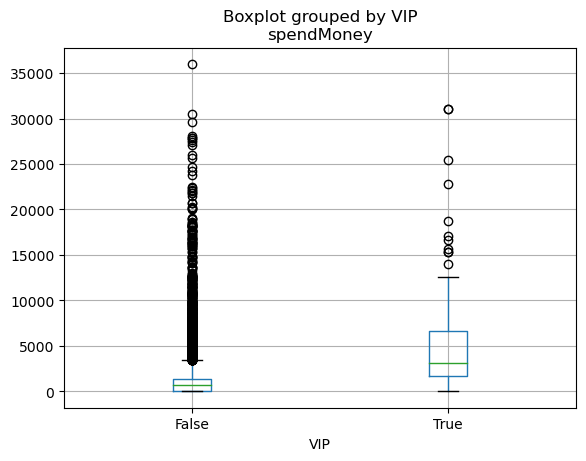

In [175]:
import matplotlib.pyplot as plt

train_df.boxplot(column='spendMoney', by='VIP')
plt.show()

In [176]:
train_df['VIP'] = train_df['VIP'].fillna(0)

In [177]:
test_df['VIP'] = test_df['VIP'].fillna(0)

In [178]:
train_df['VIP'] = train_df['VIP'].astype(int)

In [179]:
test_df['CryoSleep'] = test_df['CryoSleep'].astype(int)

In [180]:
test_df['VIP'] = test_df['VIP'].astype(int)

In [181]:
train_df.dtypes

CryoSleep                int64
Cabin                   object
Age                    float64
VIP                      int64
RoomService            float64
FoodCourt              float64
ShoppingMall           float64
Spa                    float64
VRDeck                 float64
Transported              int64
num                     object
side                   float64
family_group           float64
family_group_number     object
Last_name               object
spendMoney             float64
deck_A                   uint8
deck_B                   uint8
deck_C                   uint8
deck_D                   uint8
deck_E                   uint8
deck_F                   uint8
deck_G                   uint8
deck_T                   uint8
deck_Unknown             uint8
HomePlanet_Earth         uint8
HomePlanet_Europa        uint8
HomePlanet_Mars          uint8
dest_55 Cancri e         uint8
dest_PSO J318.5-22       uint8
dest_TRAPPIST-1e         uint8
dest_Unknown             uint8
side_mis

In [182]:
test_df.dtypes

CryoSleep                int64
Cabin                   object
Age                    float64
VIP                      int64
RoomService            float64
FoodCourt              float64
ShoppingMall           float64
Spa                    float64
VRDeck                 float64
Transported              int64
num                     object
side                   float64
family_group           float64
family_group_number     object
Last_name               object
spendMoney             float64
deck_A                   uint8
deck_B                   uint8
deck_C                   uint8
deck_D                   uint8
deck_E                   uint8
deck_F                   uint8
deck_G                   uint8
deck_T                   uint8
deck_Unknown             uint8
HomePlanet_Earth         uint8
HomePlanet_Europa        uint8
HomePlanet_Mars          uint8
dest_55 Cancri e         uint8
dest_PSO J318.5-22       uint8
dest_TRAPPIST-1e         uint8
dest_Unknown             uint8
side_mis

In [183]:
featured = [
    'CryoSleep','Destination','Age',
    'VIP','RoomService','FoodCourt','ShoppingMall',
    'Spa','VRDeck','family_group','deck_A',	'deck_B',	'deck_C',	'deck_D',	'deck_E',	'deck_F',	'deck_G',	'deck_T','num',
    'side','cabin_not_transported','ShoppingMall_not_transported',
    'RoomService_not_transported','spendMoney','Transported'
           ]


In [184]:
train_df['Transported'].astype(int)

0       0
1       1
2       0
3       0
4       1
       ..
8688    0
8689    0
8690    1
8691    0
8692    1
Name: Transported, Length: 8693, dtype: int64

In [185]:
train_final = train_df.select_dtypes(include=['number'])

In [186]:
test_df = test_df.select_dtypes(include=['number'])

In [187]:
train_final.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'side', 'family_group', 'spendMoney',
       'deck_A', 'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G',
       'deck_T', 'deck_Unknown', 'HomePlanet_Earth', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'dest_55 Cancri e', 'dest_PSO J318.5-22',
       'dest_TRAPPIST-1e', 'dest_Unknown', 'side_missing'],
      dtype='object')

In [188]:
test_df.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'side', 'family_group', 'spendMoney',
       'deck_A', 'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G',
       'deck_T', 'deck_Unknown', 'HomePlanet_Earth', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'dest_55 Cancri e', 'dest_PSO J318.5-22',
       'dest_TRAPPIST-1e', 'dest_Unknown', 'side_missing'],
      dtype='object')

In [189]:
# train_final = train_df[featured]

In [190]:
train_final.shape

(8693, 29)

In [191]:
train_final.isna().sum()

CryoSleep             0
Age                   0
VIP                   0
RoomService           0
FoodCourt             0
ShoppingMall          0
Spa                   0
VRDeck                0
Transported           0
side                  0
family_group          0
spendMoney            0
deck_A                0
deck_B                0
deck_C                0
deck_D                0
deck_E                0
deck_F                0
deck_G                0
deck_T                0
deck_Unknown          0
HomePlanet_Earth      0
HomePlanet_Europa     0
HomePlanet_Mars       0
dest_55 Cancri e      0
dest_PSO J318.5-22    0
dest_TRAPPIST-1e      0
dest_Unknown          0
side_missing          0
dtype: int64

In [192]:
# train_df.groupby('HomePlanet')['Age'].median()

In [193]:
train_df.groupby('VIP')['Age'].median()

VIP
0    27.0
1    34.0
Name: Age, dtype: float64

In [194]:
train_df

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
0,0,B/0/P,39.0,0,0.0,0.0,0.0,0.0,0.0,0,...,0,0,0,1,0,0,0,1,0,0
1,0,F/0/S,24.0,0,109.0,9.0,25.0,549.0,44.0,1,...,0,0,1,0,0,0,0,1,0,0
2,0,A/0/S,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,...,0,0,0,1,0,0,0,1,0,0
3,0,A/0/S,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,...,0,0,0,1,0,0,0,1,0,0
4,0,F/1/S,16.0,0,303.0,70.0,151.0,565.0,2.0,1,...,0,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,0,A/98/P,41.0,1,0.0,6819.0,0.0,1643.0,74.0,0,...,0,0,0,1,0,1,0,0,0,0
8689,1,G/1499/S,18.0,0,0.0,0.0,0.0,0.0,0.0,0,...,0,0,1,0,0,0,1,0,0,0
8690,0,G/1500/S,26.0,0,0.0,0.0,1872.0,1.0,0.0,1,...,0,0,1,0,0,0,0,1,0,0
8691,0,E/608/S,32.0,0,0.0,1049.0,0.0,353.0,3235.0,0,...,0,0,0,1,0,1,0,0,0,0


In [195]:
# train_df['HomePlanet'].value_counts()

In [196]:
train_df['Age'].isna().sum()

0

In [197]:
train_df.loc[train_df['Age'].isna(),:]

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing


In [198]:
train_df.loc[( (train_df['spendMoney'] == 0) & (train_df['CryoSleep'] == 0) ),['spendMoney', 'RoomService',	'FoodCourt', 'ShoppingMall', 'Spa',	'VRDeck', 'Age', 'CryoSleep']]['Age'].value_counts()

0.0     104
7.0      34
4.0      34
8.0      31
3.0      27
2.0      26
9.0      26
11.0     26
12.0     25
10.0     24
1.0      23
6.0      23
5.0      10
26.0      7
19.0      6
22.0      6
21.0      5
20.0      5
28.0      5
25.0      5
37.0      5
31.0      4
27.0      4
44.0      3
38.0      3
35.0      3
29.0      3
32.0      3
53.0      3
36.0      2
57.0      2
33.0      2
40.0      2
39.0      2
14.0      2
18.0      2
30.0      2
56.0      2
60.0      1
17.0      1
59.0      1
13.0      1
34.0      1
49.0      1
71.0      1
54.0      1
16.0      1
51.0      1
24.0      1
45.0      1
52.0      1
48.0      1
41.0      1
Name: Age, dtype: int64

In [199]:
median_child_age = train_df.loc[
    (train_df['spendMoney'] == 0) & (train_df['CryoSleep'] == False), 'Age'
].median()

print(median_child_age)

7.0


In [200]:
train_df.loc[(train_df['Age'].isna() & train_df['spendMoney'] == 0 ),:]

,CryoSleep,Cabin,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
0,0,B/0/P,39.0,0,0.0,0.0,0.0,0.0,0.0,0,...,0,0,0,1,0,0,0,1,0,0
1,0,F/0/S,24.0,0,109.0,9.0,25.0,549.0,44.0,1,...,0,0,1,0,0,0,0,1,0,0
2,0,A/0/S,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,...,0,0,0,1,0,0,0,1,0,0
3,0,A/0/S,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,...,0,0,0,1,0,0,0,1,0,0
4,0,F/1/S,16.0,0,303.0,70.0,151.0,565.0,2.0,1,...,0,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8688,0,A/98/P,41.0,1,0.0,6819.0,0.0,1643.0,74.0,0,...,0,0,0,1,0,1,0,0,0,0
8689,1,G/1499/S,18.0,0,0.0,0.0,0.0,0.0,0.0,0,...,0,0,1,0,0,0,1,0,0,0
8690,0,G/1500/S,26.0,0,0.0,0.0,1872.0,1.0,0.0,1,...,0,0,1,0,0,0,0,1,0,0
8691,0,E/608/S,32.0,0,0.0,1049.0,0.0,353.0,3235.0,0,...,0,0,0,1,0,1,0,0,0,0


In [201]:
train_df[ train_df['dest_PSO J318.5-22'] == 1 ]['Age'].median()

24.0

In [202]:
train_df[ train_df['dest_TRAPPIST-1e'] == 1 ]['Age'].median()

27.0

In [203]:
train_df[ train_df['dest_TRAPPIST-1e'] == 1 ]['Age'].median()

27.0

In [204]:
median_child_age = train_df.loc[(train_df['spendMoney'] == 0) & (train_df['CryoSleep'] == False),:]['Age'].median()

In [205]:
test_df

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,side,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
0,1,27.0,0,0.0,0.0,0.0,0.0,0.0,0,2.0,...,0,0,1,0,0,0,0,1,0,0
1,0,19.0,0,0.0,9.0,0.0,2823.0,0.0,0,2.0,...,0,0,1,0,0,0,0,1,0,0
2,1,31.0,0,0.0,0.0,0.0,0.0,0.0,0,2.0,...,0,0,0,1,0,1,0,0,0,0
3,0,38.0,0,0.0,6652.0,0.0,181.0,585.0,0,2.0,...,0,0,0,1,0,0,0,1,0,0
4,0,20.0,0,10.0,0.0,635.0,0.0,0.0,0,2.0,...,0,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4272,1,34.0,0,0.0,0.0,0.0,0.0,0.0,0,2.0,...,0,0,1,0,0,0,0,1,0,0
4273,0,42.0,0,0.0,847.0,17.0,10.0,144.0,0,0.0,...,0,1,1,0,0,0,0,1,0,0
4274,1,27.0,0,0.0,0.0,0.0,0.0,0.0,0,1.0,...,0,0,0,0,1,1,0,0,0,0
4275,0,32.0,0,0.0,2680.0,0.0,0.0,523.0,0,1.0,...,0,0,0,1,0,0,0,0,1,0


In [206]:
# for df in [train_df, test_df]:
#     df['Age'] = df['Age'].fillna(
#         df.groupby('HomePlanet')['Age'].transform('median')
#     )
#     # fallback se ainda sobrar nulo (ex: HomePlanet também nulo)
#     df['Age'] = df['Age'].fillna(df['Age'].median())

In [207]:
##

Y = train_final['Transported']
X = train_final.drop('Transported', axis=1)

In [208]:
len(X.columns)

28

In [209]:
train_final.shape

(8693, 29)

In [210]:
train_final = train_df[test_df.columns]

In [211]:
X.shape

(8693, 28)

In [212]:
## Split train and test database

X_train_split, X_valid, Y_train_split, Y_valid = train_test_split(X, Y, train_size=0.7, test_size=0.3, random_state=0)
print(" train_test_split feito")


 train_test_split feito


In [213]:
featured

['CryoSleep',
 'Destination',
 'Age',
 'VIP',
 'RoomService',
 'FoodCourt',
 'ShoppingMall',
 'Spa',
 'VRDeck',
 'family_group',
 'deck_A',
 'deck_B',
 'deck_C',
 'deck_D',
 'deck_E',
 'deck_F',
 'deck_G',
 'deck_T',
 'num',
 'side',
 'cabin_not_transported',
 'ShoppingMall_not_transported',
 'RoomService_not_transported',
 'spendMoney',
 'Transported']

In [214]:

# ##Análise de features
# import time
# import itertools
# tempo_inicial = time.time()





# lst = featured
# lista_resultado = pd.DataFrame(columns=featured)
# lista_combinacoes = []



# for r in range(1, len(lst)+1):
#     combinations = itertools.combinations(lst, r)
#     for combo in combinations:
#         if ('passengerid' in combo) and ('survived' in combo) and len(combo) > 2 and ('deck' not in combo or 'deck_criado' not in combo) and ('age' not in combo or 'age_criado' not in combo):
#             lista_combinacoes.append(combo)
#             df_gerado = pd.DataFrame(df, columns=combo)
#             if 'deck' in combo:
#                 df_gerado['deck'].fillna(-1, inplace=True)

#             # dividir por teste e treino
#             df_test = df_gerado[df_gerado['survived'].isna()]
#             df_train = df_gerado[df_gerado['survived'].notna()]    
            
#             # sepando dados alvo
#             X = train_final.drop('survived', axis=1)
#             y = train_final['survived']
#             df_test = df_test.drop('survived', axis=1)
            
#             # separando em dados para treinar
#             np.random.seed(0)
#             X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=41)
            
#             modelo = RandomForestClassifier(n_estimators=100, random_state=41)
            
#             # treinando
#             modelo.fit(X_train, y_train)
            
#             # fazendo previsões
#             y_pred = modelo.predict(X_test)
            
#             acc = accuracy_score(y_test, y_pred)
            
#             nova_linha = {'acc': acc, 'combinacao': str(combo)}
#             lista_resultado = lista_resultado.append(nova_linha, ignore_index=True)


            
# def funcao_calcula(combinacao):
#     df_gerado = pd.DataFrame(train_final, columns=combo)
#     if 'deck' in combo:
#        df_gerado['deck'].fillna(-1, inplace=True)
        
#     #dividir por teste e treino
#     df_test = df_gerado[df_gerado['Transported'].isna()]
#     df_train = df_gerado[df_gerado['Transported'].notna()]        
    
#     #sepando dados alvo
#     X = df_train.drop('Transported', axis=1)
#     y = df_train['Transported']
#     df_test = df_test.drop('Transported', axis=1)
    
#     #separando em dados para treinar
#     #np.random.seed(0)
#     X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=41)
    
#     modelo = RandomForestClassifier(n_estimators=100, random_state=41)
            
#     #treinando
#     modelo.fit(X_train, y_train)
            
#     #fazendo previsões
#     y_pred = modelo.predict(X_test)
            
#     acc = accuracy_score(y_test, y_pred)
            
#     nova_linha = {'acc': acc, 'combinacao': str(combo)}
    
#     return(nova_linha)


# resultado = Parallel(n_jobs=-1)(delayed(funcao_calcula)(combinacao) for combinacao in lista_combinacoes)    


# print(f"Demorou: {time.time() - tempo_inicial}")



In [215]:
train_final.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,side,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
0,0,39.0,0,0.0,0.0,0.0,0.0,0.0,0,1.0,...,0,0,0,1,0,0,0,1,0,0
1,0,24.0,0,109.0,9.0,25.0,549.0,44.0,1,2.0,...,0,0,1,0,0,0,0,1,0,0
2,0,58.0,1,43.0,3576.0,0.0,6715.0,49.0,0,2.0,...,0,0,0,1,0,0,0,1,0,0
3,0,33.0,0,0.0,1283.0,371.0,3329.0,193.0,0,2.0,...,0,0,0,1,0,0,0,1,0,0
4,0,16.0,0,303.0,70.0,151.0,565.0,2.0,1,2.0,...,0,0,1,0,0,0,0,1,0,0


In [216]:
X_train_split.shape

(6085, 28)

In [217]:
X_valid.shape

(2608, 28)

In [218]:
# X_test = test_df

In [219]:
X_train_split.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'side', 'family_group', 'spendMoney', 'deck_A',
       'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_T',
       'deck_Unknown', 'HomePlanet_Earth', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'dest_55 Cancri e', 'dest_PSO J318.5-22',
       'dest_TRAPPIST-1e', 'dest_Unknown', 'side_missing'],
      dtype='object')

In [220]:
X_train_split

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,side,family_group,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
7289,0,64.0,0,19.000000,261.0,208.0,0.000000,214.0,2.0,7791.0,...,0,0,1,0,0,1,0,0,0,0
2709,0,24.0,0,222.751106,2.0,25.0,308.744286,707.0,1.0,2901.0,...,0,0,1,0,0,0,1,0,0,0
6803,0,44.0,0,0.000000,0.0,16.0,72.000000,4304.0,1.0,7186.0,...,0,0,0,1,0,0,0,1,0,0
3731,0,34.0,0,0.000000,847.0,14.0,0.000000,0.0,2.0,4001.0,...,0,0,1,0,0,0,0,0,1,0
6333,0,13.0,0,0.000000,0.0,0.0,0.000000,0.0,1.0,6699.0,...,0,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4373,1,32.0,0,0.000000,0.0,0.0,0.000000,0.0,1.0,4655.0,...,0,0,0,1,0,1,0,0,0,0
7891,0,22.0,0,0.000000,0.0,6.0,0.000000,733.0,2.0,8423.0,...,0,0,1,0,0,0,0,1,0,0
4859,0,29.0,0,523.000000,0.0,21.0,4.000000,811.0,2.0,5185.0,...,0,0,0,0,1,0,0,1,0,0
3264,0,0.0,0,0.000000,0.0,0.0,0.000000,0.0,1.0,3499.0,...,0,0,1,0,0,0,0,1,0,0


In [221]:
X_train_split

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,side,family_group,...,deck_T,deck_Unknown,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,dest_55 Cancri e,dest_PSO J318.5-22,dest_TRAPPIST-1e,dest_Unknown,side_missing
7289,0,64.0,0,19.000000,261.0,208.0,0.000000,214.0,2.0,7791.0,...,0,0,1,0,0,1,0,0,0,0
2709,0,24.0,0,222.751106,2.0,25.0,308.744286,707.0,1.0,2901.0,...,0,0,1,0,0,0,1,0,0,0
6803,0,44.0,0,0.000000,0.0,16.0,72.000000,4304.0,1.0,7186.0,...,0,0,0,1,0,0,0,1,0,0
3731,0,34.0,0,0.000000,847.0,14.0,0.000000,0.0,2.0,4001.0,...,0,0,1,0,0,0,0,0,1,0
6333,0,13.0,0,0.000000,0.0,0.0,0.000000,0.0,1.0,6699.0,...,0,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4373,1,32.0,0,0.000000,0.0,0.0,0.000000,0.0,1.0,4655.0,...,0,0,0,1,0,1,0,0,0,0
7891,0,22.0,0,0.000000,0.0,6.0,0.000000,733.0,2.0,8423.0,...,0,0,1,0,0,0,0,1,0,0
4859,0,29.0,0,523.000000,0.0,21.0,4.000000,811.0,2.0,5185.0,...,0,0,0,0,1,0,0,1,0,0
3264,0,0.0,0,0.000000,0.0,0.0,0.000000,0.0,1.0,3499.0,...,0,0,1,0,0,0,0,1,0,0


In [222]:
# X_test.columns

In [223]:
## Transform boolean variable True/False into 1/0

y_valid = Y_valid.astype(int)

In [224]:
y_valid

3601    1
6057    1
2797    0
7110    0
8579    1
       ..
7081    1
2873    1
3420    1
535     1
5117    0
Name: Transported, Length: 2608, dtype: int64

In [225]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_split)
X_valid_scaled = scaler.transform(X_valid)

In [226]:
## Logistic regression
logreg = LogisticRegression(solver='lbfgs', max_iter=10000)
logreg.fit(X_train_scaled, Y_train_split)
Y_pred = logreg.predict(X_valid_scaled)

acc_log_score = round(logreg.score(X_valid_scaled, Y_valid) * 100, 2)

acc_log_score

79.06

In [227]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(solver='lbfgs', max_iter=10000, random_state=42))
])

In [228]:
scores = cross_val_score(pipeline, X_train_scaled, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79539852 0.78800329 0.78471652 0.80608053 0.78800329]
Média: 0.7924404272801973
Desvio padrão: 0.007666000847783492


In [229]:
lr_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",lr_accuracy_score)

 Accuracy score:  79.06441717791411


In [230]:
##
svc = SVC(probability=True)
svc.fit(X_train_scaled, Y_train_split)
Y_pred = svc.predict(X_valid_scaled)

acc_svc_score = round(svc.score(X_valid_scaled, y_valid) * 100, 2)
acc_svc_score

78.76

In [231]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(max_iter=5000, random_state=42))  # ou -1 (sem limite)
])

In [232]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.78964667 0.78225144 0.8085456  0.80772391 0.79868529]
Média: 0.7973705834018078
Desvio padrão: 0.010218104556588215


In [233]:
svc_accuracy_score = accuracy_score(y_valid, Y_pred) * 100
print("Accuracy score: ", svc_accuracy_score)

Accuracy score:  78.75766871165644


In [234]:
##
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(X_train_scaled, Y_train_split)
Y_pred = knn.predict(X_valid_scaled)

acc_knn_score = round(knn.score(X_valid_scaled, Y_valid) * 100, 2)

acc_knn_score

76.65

In [235]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors = 3))
])

In [236]:
scores = cross_val_score(pipeline, X_train_scaled, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.77403451 0.75677896 0.76746097 0.75184881 0.75349219]
Média: 0.760723089564503
Desvio padrão: 0.008592878529105239


In [237]:
knn_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",knn_accuracy_score)

 Accuracy score:  76.64877300613497


In [238]:
##
gaussian = GaussianNB()
gaussian.fit(X_train_scaled, Y_train_split)
Y_pred = gaussian.predict(X_valid_scaled)

acc_gaussian_score = round(gaussian.score(X_valid_scaled, Y_valid) * 100, 2)

acc_gaussian_score

69.06

In [239]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', GaussianNB())
])

In [240]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [241]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.71487264 0.6072309  0.71240756 0.73130649 0.71322925]
Média: 0.6958093672966311
Desvio padrão: 0.044829793915806604


In [242]:
gaussian_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",gaussian_accuracy_score)

 Accuracy score:  69.05674846625767


In [243]:
##

perceptron = Perceptron()
perceptron.fit(X_train_scaled, Y_train_split)
Y_pred = perceptron.predict(X_valid_scaled)

acc_perceptron_score = round(perceptron.score(X_valid_scaled, Y_valid) * 100, 2)

acc_perceptron_score

77.03

In [244]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Perceptron())
])

In [245]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [246]:
perceptron_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",perceptron_accuracy_score)

 Accuracy score:  77.03220858895705


In [247]:

##
linear_svc = LinearSVC(max_iter=480000)
linear_svc.fit(X_train_scaled, Y_train_split)
Y_pred = linear_svc.predict(X_valid_scaled)

acc_linear_svc_score = round(linear_svc.score(X_valid_scaled, Y_valid) * 100, 2)

acc_linear_svc_score

79.03

In [248]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearSVC(max_iter=480000, random_state=42))
])

In [249]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [250]:
print("Scores:", scores)
print("Média:", scores.mean())

Scores: [0.79129006 0.78718159 0.78718159 0.79950698 0.78800329]
Média: 0.79063270336894


In [251]:
linear_svc_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",linear_svc_accuracy_score)

 Accuracy score:  79.0260736196319


In [252]:
##
sgd = SGDClassifier()
sgd.fit(X_train_scaled, Y_train_split)
Y_pred = sgd.predict(X_valid_scaled)

acc_sgd_score = round(sgd.score(X_valid_scaled, Y_valid) * 100, 2)

acc_sgd_score

77.07

In [253]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SGDClassifier(max_iter=1000, random_state=42))
])

In [254]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [255]:
print("Scores:", scores)
print("Média:", scores.mean())

Scores: [0.77321282 0.77814297 0.78225144 0.78389482 0.77239113]
Média: 0.7779786359901397


In [256]:
sgd_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",sgd_accuracy_score)

 Accuracy score:  77.07055214723927


In [257]:
##
decision_tree = DecisionTreeClassifier()
decision_tree.fit(X_train_split, Y_train_split)
Y_pred = decision_tree.predict(X_valid)

acc_decision_tree_score = round(decision_tree.score(X_valid, Y_valid) * 100, 2)

acc_decision_tree_score

75.96

In [258]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', DecisionTreeClassifier())
])

In [259]:
scores = cross_val_score(pipeline, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [260]:
print("Scores:", scores)
print("Média:", scores.mean())

Scores: [0.72226787 0.72884141 0.75842235 0.74856204 0.72308956]
Média: 0.7362366474938373


In [261]:
dt_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",dt_accuracy_score)

 Accuracy score:  75.95858895705521


In [262]:
##
random_forest = RandomForestClassifier(n_estimators=300, random_state=42)
random_forest.fit(X_train_split, Y_train_split)
Y_pred = random_forest.predict(X_valid)

random_forest.score(X_train_split, Y_train_split)
acc_random_forest_score = round(random_forest.score(X_valid, Y_valid) * 100, 2)

acc_random_forest_score

79.98

In [263]:
scores = cross_val_score(random_forest, X_train_split, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.80525883 0.78225144 0.79868529 0.80361545 0.79211175]
Média: 0.7963845521774855
Desvio padrão: 0.008418240575096622


In [264]:
rf_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",rf_accuracy_score)

 Accuracy score:  79.98466257668711


In [265]:
X_train_split.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 6085 entries, 7289 to 2732
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CryoSleep           6085 non-null   int64  
 1   Age                 6085 non-null   float64
 2   VIP                 6085 non-null   int64  
 3   RoomService         6085 non-null   float64
 4   FoodCourt           6085 non-null   float64
 5   ShoppingMall        6085 non-null   float64
 6   Spa                 6085 non-null   float64
 7   VRDeck              6085 non-null   float64
 8   side                6085 non-null   float64
 9   family_group        6085 non-null   float64
 10  spendMoney          6085 non-null   float64
 11  deck_A              6085 non-null   uint8  
 12  deck_B              6085 non-null   uint8  
 13  deck_C              6085 non-null   uint8  
 14  deck_D              6085 non-null   uint8  
 15  deck_E              6085 non-null   uint8  
 16  dec

In [266]:

lgbm_Classifier = LGBMClassifier(n_estimators=100)
lgbm_Classifier.fit(X_train_split, Y_train_split)
Y_pred = lgbm_Classifier.predict(X_valid)


lgbm_Classifier.score(X_train_split, Y_train_split)
lgbm_Classifier_score = round(lgbm_Classifier.score(X_valid, Y_valid) * 100, 2)

lgbm_Classifier_score

80.9

In [267]:
scores = cross_val_score(lgbm_Classifier, X_train_split, Y_train_split, cv=5, scoring='accuracy')

print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.80690222 0.78800329 0.80525883 0.82580115 0.80115037]
Média: 0.8054231717337716
Desvio padrão: 0.012158830772781558


In [268]:
lgbm_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",lgbm_accuracy_score)

 Accuracy score:  80.90490797546013


In [269]:
## Training in CatBoostClassifier
catboost_classifier = CatBoostClassifier(iterations=10,learning_rate=1,depth=2)
catboost_classifier.fit(X_train_split, Y_train_split)
Y_pred = catboost_classifier.predict(X_valid)


catboost_classifier.score(X_train_split, Y_train_split)
catboost_classifier_score = round(catboost_classifier.score(X_valid, Y_valid) * 100, 2)

catboost_classifier_score

0:	learn: 0.5624917	total: 59.2ms	remaining: 533ms
1:	learn: 0.5384879	total: 61.5ms	remaining: 246ms
2:	learn: 0.5075440	total: 63.3ms	remaining: 148ms
3:	learn: 0.4827309	total: 65.1ms	remaining: 97.7ms
4:	learn: 0.4698426	total: 67ms	remaining: 67ms
5:	learn: 0.4597167	total: 68.4ms	remaining: 45.6ms
6:	learn: 0.4501971	total: 70ms	remaining: 30ms
7:	learn: 0.4451325	total: 71.7ms	remaining: 17.9ms
8:	learn: 0.4398291	total: 73.5ms	remaining: 8.17ms
9:	learn: 0.4351276	total: 75.2ms	remaining: 0us


78.41

In [270]:
scores = cross_val_score(catboost_classifier, X_train_split, Y_train_split, cv=5, scoring='accuracy')

0:	learn: 0.5585571	total: 1.86ms	remaining: 16.8ms
1:	learn: 0.5324573	total: 3.59ms	remaining: 14.4ms
2:	learn: 0.5147317	total: 5ms	remaining: 11.7ms
3:	learn: 0.4923188	total: 6.55ms	remaining: 9.82ms
4:	learn: 0.4779653	total: 7.95ms	remaining: 7.95ms
5:	learn: 0.4702878	total: 9.36ms	remaining: 6.24ms
6:	learn: 0.4644429	total: 10.6ms	remaining: 4.56ms
7:	learn: 0.4587363	total: 12.1ms	remaining: 3.01ms
8:	learn: 0.4513863	total: 13.5ms	remaining: 1.5ms
9:	learn: 0.4407865	total: 14.9ms	remaining: 0us
0:	learn: 0.5603562	total: 1.72ms	remaining: 15.4ms
1:	learn: 0.5309866	total: 3.34ms	remaining: 13.4ms
2:	learn: 0.5079667	total: 4.82ms	remaining: 11.3ms
3:	learn: 0.4829648	total: 6.1ms	remaining: 9.14ms
4:	learn: 0.4722958	total: 7.49ms	remaining: 7.49ms
5:	learn: 0.4623030	total: 9.03ms	remaining: 6.02ms
6:	learn: 0.4583238	total: 10.6ms	remaining: 4.55ms
7:	learn: 0.4466501	total: 12.2ms	remaining: 3.04ms
8:	learn: 0.4383012	total: 13.6ms	remaining: 1.51ms
9:	learn: 0.4328136	

In [271]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.79211175 0.7756779  0.78882498 0.80772391 0.79704191]
Média: 0.7922760887428102
Desvio padrão: 0.010476501200006047


In [272]:
catboost_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",catboost_accuracy_score)

 Accuracy score:  78.41257668711657


In [273]:
## XGBClassifier
xgbboost_classifier = XGBClassifier(learning_rate=1,max_depth=2)
xgbboost_classifier.fit(X_train_split, Y_train_split)
Y_pred = xgbboost_classifier.predict(X_valid)


xgbboost_classifier.score(X_train_split, Y_train_split)
xgbboost_classifier_score = round(xgbboost_classifier.score(X_valid, Y_valid) * 100, 2)

xgbboost_classifier_score

79.52

In [274]:
scores = cross_val_score(xgbboost_classifier, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [275]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.80115037 0.76910435 0.79539852 0.80361545 0.79950698]
Média: 0.7937551355792933
Desvio padrão: 0.012612380512308898


In [276]:
xgbboost_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",xgbboost_accuracy_score)

 Accuracy score:  79.52453987730061


In [277]:
from sklearn.neural_network import MLPClassifier

In [278]:
MLPClassifier_classifier = MLPClassifier(alpha=1, max_iter=1000, random_state=42)

MLPClassifier_classifier.fit(X_train_scaled, Y_train_split)
Y_pred = MLPClassifier_classifier.predict(X_valid_scaled)


MLPClassifier_classifier.score(X_train_scaled, Y_train_split)
MLPClassifier_classifier_score = round(MLPClassifier_classifier.score(X_valid_scaled, Y_valid) * 100, 2)

MLPClassifier_classifier_score

79.64

In [279]:
scores = cross_val_score(random_forest, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [280]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.80525883 0.78225144 0.79868529 0.80361545 0.79211175]
Média: 0.7963845521774855
Desvio padrão: 0.008418240575096622


In [281]:
MLPClassifier_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ", MLPClassifier_accuracy_score)

 Accuracy score:  79.63957055214725


In [282]:
extra_trees_classifier = ExtraTreesClassifier(n_estimators=500, random_state=42)

extra_trees_classifier.fit(X_train_split, Y_train_split)
Y_pred = extra_trees_classifier.predict(X_valid)


extra_trees_classifier.score(X_train_split, Y_train_split)
extra_trees_classifier_score = round(extra_trees_classifier.score(X_valid, Y_valid) * 100, 2)

extra_trees_classifier_score

79.72

In [283]:
scores = cross_val_score(extra_trees_classifier, X_train_split, Y_train_split, cv=5, scoring='accuracy')

In [284]:
print("Scores por fold:", scores)
print("Média:", scores.mean())
print("Desvio padrão:", scores.std())

Scores por fold: [0.80032868 0.78718159 0.78964667 0.79704191 0.78882498]
Média: 0.7926047658175842
Desvio padrão: 0.005134100033463712


In [285]:
extra_trees_accuracy_score = accuracy_score(y_valid,Y_pred) * 100
print(" Accuracy score: ",extra_trees_accuracy_score)

 Accuracy score:  79.71625766871165


In [286]:
# print("X_test:", X_test.shape)
# print("passenger_ids:", len(passenger_ids))

In [287]:
# X_train

In [288]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict

## Ensemble Evaluation and Submission

This function evaluates multiple binary classifiers and combines their predictions using **weighted soft voting**.

### How it works

1. **Out-of-fold evaluation:** `StratifiedKFold` splits the training data into folds while preserving class proportions. Each model predicts rows that were not used to train it. These out-of-fold (OOF) predictions provide an estimate of accuracy on unseen data.
2. **Soft voting:** The function computes a weighted average of the models’ predicted probabilities. It assigns the positive class when the combined probability is at least `0.5`.
3. **Submission generation:** Each model is retrained on the full training set. Their probabilities for `X_test` are combined, paired with `passenger_ids`, and saved as a CSV file.

### Important notes

- Each estimator must support `predict_proba`.
- Put preprocessing steps inside each model’s `Pipeline` to prevent data leakage during cross-validation.
- `X_test` and `passenger_ids` must have the same number of rows and matching order.
- With `weights=None`, all models receive equal weight. Custom weights are normalized automatically.
- An ensemble is not guaranteed to outperform the best individual model. Compare their OOF accuracy before choosing the models and weights.

In [289]:
## Final table with algorithms, score and absolute mean error
models = pd.DataFrame({
    'Model': ['Support Vector Machines', 'KNN', 'Logistic Regression', 
              'Naive Bayes', 'Random Forest', 'Perceptron', 
              'Stochastic Gradient Decent', 'Linear SVC', 
              'Decision Tree','LGBM Classifier','Cat Boost Classifier','XGBoost Classifier', 'extra_trees_classifier_score', 'MLPClassifier_classifier_score'],
    'Score': [acc_svc_score, acc_knn_score, acc_log_score, acc_gaussian_score,
              acc_random_forest_score, acc_perceptron_score, 
              acc_sgd_score, acc_linear_svc_score, acc_decision_tree_score,lgbm_Classifier_score,
              catboost_classifier_score,xgbboost_classifier_score, extra_trees_classifier_score, MLPClassifier_classifier_score],

    
    'accuracy_score' : [svc_accuracy_score,knn_accuracy_score,lr_accuracy_score,
                    gaussian_accuracy_score, rf_accuracy_score, perceptron_accuracy_score,
                    sgd_accuracy_score, linear_svc_accuracy_score,dt_accuracy_score,
                   lgbm_accuracy_score,catboost_accuracy_score, 
                    xgbboost_accuracy_score, extra_trees_accuracy_score, MLPClassifier_accuracy_score]})
models.sort_values(by='accuracy_score', ascending=False)

,Model,Score,accuracy_score
9,LGBM Classifier,80.90,80.904908
4,Random Forest,79.98,79.984663
12,extra_trees_classifier_score,79.72,79.716258
13,MLPClassifier_classifier_score,79.64,79.639571
11,XGBoost Classifier,79.52,79.524540
2,Logistic Regression,79.06,79.064417
7,Linear SVC,79.03,79.026074
0,Support Vector Machines,78.76,78.757669
10,Cat Boost Classifier,78.41,78.412577
6,Stochastic Gradient Decent,77.07,77.070552


In [290]:
from sklearn.calibration import CalibratedClassifierCV

In [291]:
modelo_calibrado_Perceptron = CalibratedClassifierCV(Perceptron(), method='sigmoid', cv=5)
modelo_calibrado_modelo_calibrado_LinearSVC = CalibratedClassifierCV(LinearSVC(), method='sigmoid', cv=5)
modelo_calibrado_Calibrated_SGDClassifier = CalibratedClassifierCV(SGDClassifier(loss='hinge'), method='sigmoid', cv=5)
modelo_calibrado_Calibrated_MLPClassifier = CalibratedClassifierCV(MLPClassifier(alpha=1, max_iter=1000, random_state=42), method='sigmoid', cv=5)

In [292]:
extra_trees_classifier = ExtraTreesClassifier(n_estimators=500, random_state=42)

extra_trees_classifier.fit(X_train_split, Y_train_split)
Y_pred = extra_trees_classifier.predict(X_valid)

In [293]:
models.sort_values(by='accuracy_score', ascending=False)

,Model,Score,accuracy_score
9,LGBM Classifier,80.90,80.904908
4,Random Forest,79.98,79.984663
12,extra_trees_classifier_score,79.72,79.716258
13,MLPClassifier_classifier_score,79.64,79.639571
11,XGBoost Classifier,79.52,79.524540
2,Logistic Regression,79.06,79.064417
7,Linear SVC,79.03,79.026074
0,Support Vector Machines,78.76,78.757669
10,Cat Boost Classifier,78.41,78.412577
6,Stochastic Gradient Decent,77.07,77.070552


In [294]:
estimators = {
    "logreg":logreg,
    "svc":svc,
    "knn":knn,
    "gaussian":gaussian,
    "perceptron":modelo_calibrado_Perceptron,
    "linear_svc":modelo_calibrado_modelo_calibrado_LinearSVC,
    "sgd":modelo_calibrado_Calibrated_SGDClassifier,
    "decision_tree":decision_tree,
    "random_forest":random_forest,
    "lgbm_Classifier":lgbm_Classifier,
    "catboost_classifier":catboost_classifier,
    "xgbboost_classifier":xgbboost_classifier,
    "extra_trees_classifier":extra_trees_classifier,
    # "MLPClassifier_classifier_score":modelo_calibrado_Calibrated_MLPClassifier
}

In [295]:
X_train_split.shape

(6085, 28)

In [296]:
X_valid.shape

(2608, 28)

In [297]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

In [298]:
stack = StackingClassifier(
    estimators=list(estimators.items()),
    final_estimator=LogisticRegression(max_iter=30000),
    cv=5,
    stack_method="predict_proba",
    n_jobs=-1,
    passthrough=True,
)

In [299]:
stack.fit(X_train_split, Y_train_split)
y_pred = stack.predict(X_valid)

/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,


0:	learn: 0.5624917	total: 2.04ms	remaining: 18.3ms
1:	learn: 0.5384879	total: 3.88ms	remaining: 15.5ms
2:	learn: 0.5075440	total: 5.8ms	remaining: 13.5ms
3:	learn: 0.4827309	total: 7.53ms	remaining: 11.3ms
4:	learn: 0.4698426	total: 9.3ms	remaining: 9.3ms
5:	learn: 0.4597167	total: 10.7ms	remaining: 7.15ms
6:	learn: 0.4501971	total: 12.2ms	remaining: 5.24ms
7:	learn: 0.4451325	total: 14ms	remaining: 3.49ms
8:	learn: 0.4398291	total: 15.7ms	remaining: 1.75ms
9:	learn: 0.4351276	total: 17.3ms	remaining: 0us


/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  ConvergenceWarning,
/opt/conda/lib/python3.7/site-packages/sklearn/svm/_base.py:1208: ConvergenceWarning: Liblinear failed to converge, increase the number

0:	learn: 0.5585571	total: 1.87ms	remaining: 16.9ms
1:	learn: 0.5324573	total: 3.73ms	remaining: 14.9ms
2:	learn: 0.5147317	total: 5.23ms	remaining: 12.2ms
3:	learn: 0.4923188	total: 6.84ms	remaining: 10.3ms
4:	learn: 0.4779653	total: 8.22ms	remaining: 8.22ms
5:	learn: 0.4702878	total: 9.53ms	remaining: 6.36ms
6:	learn: 0.4644429	total: 10.9ms	remaining: 4.67ms
7:	learn: 0.4587363	total: 12.2ms	remaining: 3.05ms
8:	learn: 0.4513863	total: 13.8ms	remaining: 1.53ms
9:	learn: 0.4407865	total: 15ms	remaining: 0us
0:	learn: 0.5603562	total: 1.73ms	remaining: 15.6ms
1:	learn: 0.5309866	total: 3.48ms	remaining: 13.9ms
2:	learn: 0.5079667	total: 5ms	remaining: 11.7ms
3:	learn: 0.4829648	total: 6.32ms	remaining: 9.48ms
4:	learn: 0.4722958	total: 7.8ms	remaining: 7.8ms
5:	learn: 0.4623030	total: 9.33ms	remaining: 6.22ms
6:	learn: 0.4583238	total: 11.5ms	remaining: 4.95ms
7:	learn: 0.4466501	total: 13.2ms	remaining: 3.31ms
8:	learn: 0.4383012	total: 14.5ms	remaining: 1.61ms
9:	learn: 0.4328136	to

In [300]:
len(X.columns)

28

In [301]:
len(train_df.columns)

33

In [302]:
test_df.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'Transported', 'side', 'family_group', 'spendMoney',
       'deck_A', 'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G',
       'deck_T', 'deck_Unknown', 'HomePlanet_Earth', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'dest_55 Cancri e', 'dest_PSO J318.5-22',
       'dest_TRAPPIST-1e', 'dest_Unknown', 'side_missing'],
      dtype='object')

In [303]:
X_train_split.columns

Index(['CryoSleep', 'Age', 'VIP', 'RoomService', 'FoodCourt', 'ShoppingMall',
       'Spa', 'VRDeck', 'side', 'family_group', 'spendMoney', 'deck_A',
       'deck_B', 'deck_C', 'deck_D', 'deck_E', 'deck_F', 'deck_G', 'deck_T',
       'deck_Unknown', 'HomePlanet_Earth', 'HomePlanet_Europa',
       'HomePlanet_Mars', 'dest_55 Cancri e', 'dest_PSO J318.5-22',
       'dest_TRAPPIST-1e', 'dest_Unknown', 'side_missing'],
      dtype='object')

In [304]:
stack_accuracy_score = accuracy_score(y_valid,Y_pred)
print(f"Stacking accuracy: {stack_accuracy_score:.4f}")

Stacking accuracy: 0.7972


In [305]:
Y_pred_total = stack.predict(test_df[X_train_split.columns])

In [306]:
Y_pred_total

array([1, 0, 1, ..., 1, 1, 1])

In [307]:
# submission_final['Transported'] = submission_final['Transported'].replace({1:True,0:False})
# submission_final

In [308]:
Y_pred_total = Y_pred_total.astype(bool)
Y_pred_total

array([ True, False,  True, ...,  True,  True,  True])

In [309]:
# submission1.to_csv("submission.csv", index=False)

# print(" File submission.csv already ")

In [310]:
# # Submit notebooks to the challenge

submission_final = pd.DataFrame({
        "PassengerId": PassengerId,
        "Transported": Y_pred_total
    })

submission_final.to_csv('submission.csv', index=False)